<a href="https://colab.research.google.com/github/julandd2009/Energy_data_generation/blob/main/Hawkes_Epex_attelier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Dependencies

In [1]:
# Core libraries
import os
import time
import pickle
import itertools
import calendar
from concurrent.futures import ProcessPoolExecutor
from typing import Dict, List
# Numerical and scientific computing
import numpy as np
np.random.seed(42)
from numpy.polynomial import Polynomial
from numpy.polynomial.legendre import legvander
from numpy.polynomial.legendre import Legendre

# Plotting
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as ticker
import seaborn as sns

# Data handling
import pandas as pd

# Typing
from typing import Callable, Any, List, Tuple

# Statistical modeling and diagnostics
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from patsy import dmatrix

# Scipy tools
from scipy.interpolate import interp1d
from scipy.integrate import quad
from scipy.optimize import minimize, root_scalar
from scipy.stats import uniform, shapiro, kstest, expon
from scipy.special import erf

# Torch (PyTorch)
import torch
torch.manual_seed(42)
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset


from google.colab import drive
drive.mount('/content/drive')
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive
Mounted at /content/drive


#Auxiliary Functions

In [2]:
def evaluate_piecewise_at_unit_grid(x_raw, y_raw,
                                    method='linear',
                                    fill_value='extrapolate'):
    """
    Given raw data (x_raw, y_raw), construct a piecewise function
    and evaluate it at every integer x between min(x_raw) and max(x_raw).

    Parameters
    ----------
    x_raw : array-like, shape (n,)
        The original x-coordinates (must be sortable and unique).
    y_raw : array-like, shape (n,)
        The corresponding y-values.
    method : str, optional
        Interpolation method. One of {'linear','nearest','zero','slinear','quadratic','cubic'}.
        Default: 'linear'.
    fill_value : str or float, optional
        What to do outside the original x range.
        Default: 'extrapolate' (you can also supply a constant).

    Returns
    -------
    df_grid : pandas.DataFrame
        Columns ['x','y'] sampled at x = floor(min(x_raw)), …, ceil(max(x_raw)).
    """
    # 1. Build the piecewise function directly
    f = interp1d(x_raw, y_raw, kind=method, fill_value=fill_value)

    # 2. Make the integer grid
    x_min, x_max = np.floor(x_raw[0]), np.ceil(x_raw[-1])
    x_grid = np.arange(x_min, x_max + 1, 1)

    # 3. Evaluate
    y_grid = f(x_grid)

    # 4. Package into DataFrame
    df_grid = pd.DataFrame({'Price': x_grid, 'Volume': y_grid})
    return df_grid

In [3]:
def aggregate_by_grid(gridx, x_raw, y_raw):
    """
    For each point in gridx, aggregate y_raw values based on x_raw falling
    into the interval (prev, current] — except for the first grid point,
    where we take x_raw == gridx[0].

    Parameters
    ----------
    gridx : array-like, shape (m,)
        Monotonic sequence of x-coordinates defining bin edges/points.
        e.g. [x0, x1, x2, …, x_{m-1}]
    x_raw : array-like, shape (n,)
        Raw x-coordinates of data points.
    y_raw : array-like, shape (n,)
        Corresponding y-values to be summed in each bin.

    Returns
    -------
    pd.DataFrame with columns ['x', 'y_sum'], one row per gridx entry.
    """
    import pandas as pd

    # Build DataFrame once
    df = pd.DataFrame({'x_raw': x_raw, 'y_raw': y_raw})
    out = []
    prev_edge = None

    for edge in gridx:
        if prev_edge is None:
            # first point: equality
            mask = df['x_raw'] == edge
        else:
            # half-open (prev_edge, edge]
            mask = (df['x_raw'] > prev_edge) & (df['x_raw'] <= edge)

        y_sum = df.loc[mask, 'y_raw'].sum()
        out.append({'x': edge, 'y_sum': y_sum})
        prev_edge = edge

    return pd.DataFrame(out)


In [4]:
class MinMaxNormalizer:
    def __init__(self):
        # Map hour -> {'min': float, 'max': float}
        self.normalization_dict: Dict[int, Dict[str, float]] = {}

    def fit_transform(
        self,
        df: pd.DataFrame,
        value_col: str,
        hour_col: str = "Hour"
    ) -> pd.DataFrame:
        """
        For each hour 1..24:
          - compute min & max of value_col,
          - store them,
          - normalize those rows in-place.
        Returns a new DataFrame with the normalized column.
        """
        df_norm = df.copy()
        for hour in range(1, 25):
            mask = df_norm[hour_col] == hour
            if not mask.any():
                continue

            vals = df_norm.loc[mask, value_col]
            v_min, v_max = vals.min(), vals.max()
            # Avoid division by zero if all values equal
            span = v_max - v_min or 1.0

            # Store parameters
            self.normalization_dict[hour] = {'min': v_min, 'max': v_max}

            # Apply min–max scaling
            df_norm.loc[mask, value_col] = (vals - v_min) / span

        return df_norm

    def transform(
        self,
        df: pd.DataFrame,
        value_col: str,
        hour_col: str = "Hour"
    ) -> pd.DataFrame:
        """
        Apply stored per-hour min–max parameters to new DataFrame.
        """
        df_norm = df.copy()
        for hour, params in self.normalization_dict.items():
            mask = df_norm[hour_col] == hour
            if not mask.any():
                continue

            v_min, v_max = params['min'], params['max']
            span = v_max - v_min or 1.0
            df_norm.loc[mask, value_col] = (df_norm.loc[mask, value_col] - v_min) / span

        return df_norm

    def inverse_transform(
        self,
        df: pd.DataFrame,
        value_col: str,
        hour_col: str = "Hour"
    ) -> pd.DataFrame:
        """
        Reverse the min–max scaling for each hour.
        """
        df_denorm = df.copy()
        for hour, params in self.normalization_dict.items():
            mask = df_denorm[hour_col] == hour
            if not mask.any():
                continue

            v_min, v_max = params['min'], params['max']
            span = v_max - v_min or 1.0
            df_denorm.loc[mask, value_col] = df_denorm.loc[mask, value_col] * span + v_min

        return df_denorm


#Non-homogeneous Poisson classes

In [8]:
class GridNHPP:
    def __init__(self, t_grid, T=1.0, eps=1e-3):
        """
        Non-homogeneous Poisson process with piecewise-linear intensity.

        Parameters
        ----------
        t_grid : array_like
            1D array of strictly increasing time‐points in [0, T] at which
            the intensity is estimated.
        T : float, optional
            End of the observation window.  If None, taken as t_grid[-1].
        eps : float, optional
            Minimum allowed intensity to enforce positivity.
        """
        self.t_grid = np.asarray(t_grid)
        self.eps = eps
        self.flag = None

        # precompute interval widths for the integral
        self._t_full = np.concatenate([self.t_grid, [self.T]]) if self.T > self.t_grid[-1] else self.t_grid
        self._dt = np.diff(self._t_full)

    def _intensity(self, t, lam_vals):
        """
        Piecewise-linear interpolation of intensity values.
        """
        # np.interp handles outside [t_grid] by using the endpoint values
        return np.clip(np.interp(t, self.t_grid, lam_vals), self.eps, None)

    def _cumulative_intensity(self, lam_vals):
        """
        Compute ∫₀ᵀ λ(s) ds by summing trapezoids over each interval.
        """
        # for N grid points we have N-1 intervals; if T>t_grid[-1], last interval uses constant lam
        lam_full = np.concatenate([lam_vals, [lam_vals[-1]]]) if self.T > self.t_grid[-1] else lam_vals
        # trapezoidal rule
        area = 0.5 * (lam_full[:-1] + lam_full[1:]) * self._dt
        return np.sum(area)

    def fit(self, arrivals):
        """
        Fit the grid-based intensity to the observed arrival times.

        Maximizes log L = -∫₀ᵀ λ(s) ds + ∑ᵢ log λ(tᵢ).
        """
        arrivals = np.asarray(arrivals)
        # initial guess: constant intensity equal to mean rate
        a0 = np.full_like(self.t_grid, fill_value=len(arrivals)/self.T)
        # objective: negative log-likelihood
        def nll(lam):
            lam_clipped = np.clip(lam, self.eps, None)
            integral = self._cumulative_intensity(lam_clipped)
            log_terms = np.log(self._intensity(arrivals, lam_clipped)).sum()
            return integral - log_terms

        # enforce λ ≥ eps via bounds
        bounds = [(self.eps, None)] * len(self.t_grid)
        res = minimize(nll, a0, method='L-BFGS-B', bounds=bounds)
        self.flag = res.success
        self.lam_ = np.clip(res.x, self.eps, None)
        return self

    def predict(self, t):
        """
        Evaluate the fitted intensity at arbitrary times t.
        """
        t = np.atleast_1d(t)
        return self._intensity(t, self.lam_)

    def simulate(self, grid_size=1000, random_state=None):
        """
        Simulate an NHPP on [0, T] by thinning with an envelope M.
        """
        if random_state is not None:
            np.random.seed(random_state)
        ts = np.linspace(0, self.T, grid_size)
        M = self.predict(ts).max()
        if M <= 0:
            return np.array([])
        events = []
        t = 0.0
        while True:
            w = np.random.exponential(1/M)
            t += w
            if t >= self.T:
                break
            if np.random.rand() <= self.predict(t) / M:
                events.append(t)
        return np.array(events)

    def compute_compensator(self, arrivals):
        """
        For each arrival time t_i, compute Λ(t_i) = ∫₀^{t_i} λ(s) ds,
        with piecewise‐linear λ(s) defined by self.lam_ on self.t_grid.
        """
        arrivals = np.sort(np.asarray(arrivals))
        # Build full lam and t arrays exactly as in __init__
        if self.T > self.t_grid[-1]:
            t_full = np.concatenate([self.t_grid, [self.T]])
            lam_full = np.concatenate([self.lam_, [self.lam_[-1]]])
        else:
            t_full = self.t_grid
            lam_full = self.lam_

        dt = np.diff(t_full)
        # Precompute cumulative area at each grid‐point
        cum_areas = np.zeros(len(lam_full))
        cum_areas[1:] = np.cumsum(0.5 * (lam_full[:-1] + lam_full[1:]) * dt)

        out = np.empty_like(arrivals, dtype=float)
        total_area = cum_areas[-1]

        for i, t in enumerate(arrivals):
            # If at or beyond last grid‐point, the compensator is just total_area
            if t >= t_full[-1]:
                out[i] = total_area
                continue

            # Otherwise find segment k so t_full[k] ≤ t < t_full[k+1]
            k = np.searchsorted(t_full, t, side='right') - 1
            t0, t1 = t_full[k], t_full[k+1]
            λ0, λ1 = lam_full[k], lam_full[k+1]
            Δ = t1 - t0

            # linear slope
            slope = (λ1 - λ0)/Δ if Δ > 0 else 0.0
            dt0 = t - t0
            # area over partial segment [t0, t]:
            #   ∫₀^{dt0} [λ0 + slope * s] ds
            partial = λ0*dt0 + 0.5*slope*dt0**2

            out[i] = cum_areas[k] + partial

        return out

    def goodness_of_fit(self, arrivals, show_plot=True):
        """
        QQ‐plot of the transformed inter‐arrival uniforms to assess fit.
        """
        arrivals = np.sort(np.asarray(arrivals))
        taus = self.compute_compensator(arrivals)
        deltas = np.diff(np.concatenate([[0.0], taus]))
        u = 1 - np.exp(-deltas)
        sorted_u = np.sort(u)
        n = len(sorted_u)
        probs = (np.arange(1, n+1) - 0.5) / n
        theo_q = uniform.ppf(probs)

        if show_plot:
            plt.figure(figsize=(4,4))
            plt.plot(theo_q, sorted_u, '.', linestyle='none')
            plt.plot([0,1],[0,1],'k--')
            plt.xlabel('Theoretical Uniform quantiles')
            plt.ylabel('Empirical Uniform quantiles')
            plt.axis('equal')
            plt.show()

    def minimal_goodness_of_fit(self, arrivals, alpha=0.05):
        """
        Perform a KS test on the transformed uniforms: return 1 if not rejected.
        """
        arrivals = np.sort(np.asarray(arrivals))
        taus = self.compute_compensator(arrivals)
        deltas = np.diff(np.concatenate([[0.0], taus]))
        u = 1 - np.exp(-deltas)
        D_stat, p_value = kstest(u, 'uniform')
        return int(p_value >= alpha)

In [9]:
class HawkesWithNHBackground:
    """
    Univariate Hawkes process with exponential kernel on top of
    a fixed non-homogeneous background intensity model.

    The overall intensity is:
        λ(t) = λ0(t) + α * sum_{t_i < t} exp(-β (t - t_i))
    where λ0(t) is provided by a separate model.
    """

    def __init__(self, background_model, T):
        """
        Parameters
        ----------
        background_model : object
            Must implement:
              - predict(t: array_like) -> array of λ0(t)
              - total_integral(T: float) -> ∫₀ᵀ λ0(t) dt
        T : float
            Observation window [0, T].
        """
        self.bg = background_model
        self.T = T
        self.alpha_, self.beta_ = None, None
        self.success = False

    def _neg_log_likelihood(self, params, events):
        α, β = params
        if α <= 0 or β <= 0:
            return np.inf

        # 1) Sum log-intensity at event times
        t = events
        # background part
        λ0_t = self.bg.predict(t)
        # self-exciting part: for each t_i, sum over past events
        # build matrix of differences t[i] - t[j] where j<i
        dt = t[:, None] - t[None, :]
        dt = np.tril(dt, k=-1)  # keep only j < i, lower triangle
        exp_terms = np.exp(-β * dt, where=(dt>0), out=np.zeros_like(dt))
        λt = λ0_t + α * exp_terms.sum(axis=1)
        # avoid log of zero
        if np.any(λt <= 0):
            return np.inf
        log_term = np.sum(np.log(λt))

        # 2) Integral of λ over [0, T]:
        #    ∫₀ᵀ λ0(t) dt  +  α ∑ₖ ∫_{t_k}^T e^{-β (t - t_k)} dt
        #    = bg.total_integral(T)  +  (α/β) ∑ (1 - e^{-β (T - t_k)})
        bg_int = self.bg.total_integral(self.T)
        resid = (α / β) * np.sum(1.0 - np.exp(-β * (self.T - t)))
        integral = bg_int + resid

        # Negative log-likelihood
        return integral - log_term

    def fit(self, events, α0=0.5, β0=1.0):
        """
        Fit α and β by maximizing the Hawkes log-likelihood.

        Parameters
        ----------
        events : array_like
            Sorted event times in [0, T].
        α0, β0 : float
            Initial guesses for α and β.

        Returns
        -------
        self
        """
        events = np.sort(np.asarray(events))
        bounds = [(1e-8, None), (1e-8, None)]
        res = minimize(self._neg_log_likelihood,
                       x0=np.array([α0, β0]),
                       args=(events,),
                       bounds=bounds,
                       method='L-BFGS-B')
        self.success = res.success
        if self.success:
            self.alpha_, self.beta_ = res.x
        else:
            self.alpha_, self.beta_ = None, None
        return self

    def intensity(self, t, past_events):
        """
        Compute λ(t) at times t given past_events < t.

        Parameters
        ----------
        t : array_like
            Times where to evaluate λ.
        past_events : array_like
            Event times < max(t).

        Returns
        -------
        λ : array_like
        """
        t = np.atleast_1d(t)
        λ0_t = self.bg.predict(t)
        dt = t[:, None] - np.asarray(past_events)[None, :]
        dt = np.where(dt > 0, dt, 0)
        α, β = self.alpha_, self.beta_
        return λ0_t + α * np.exp(-β * dt).sum(axis=1)

    def compensator(self, times):
        """
        Compute the compensator ∫₀ᵗ λ(s) ds at specified times.

        Useful for goodness-of-fit checks.

        Parameters
        ----------
        times : array_like
            Times in [0, T].

        Returns
        -------
        taus : array_like
        """
        times = np.sort(np.asarray(times))
        # background part
        bg_vals = np.array([self.bg.total_integral(t) for t in times])
        # self part
        α, β = self.alpha_, self.beta_
        taus = np.zeros_like(times)
        for i, t in enumerate(times):
            past = times[:i]
            taus[i] = α/β * np.sum(1 - np.exp(-β * (t - past)))
        return bg_vals + taus

#Code

In [10]:
Epex_Intersections = pd.read_csv(os.path.join('/content/drive/My Drive/A0_EcolePolytechnique Postdoc/A5_GANS/CSV_Files/Epex', "Epex_Intersections.csv"), sep=",")
Epex_Intersections['Date']=pd.to_datetime(Epex_Intersections['Date'], format="%d/%m/%Y")
Epex_Intersections['Hour']=pd.to_numeric(Epex_Intersections['Hour'], errors='coerce')

In [11]:
peaks_dates = [
    pd.to_datetime("29/09/2020", format="%d/%m/%Y"),  #19 -20     #0
    pd.to_datetime("21/09/2020", format="%d/%m/%Y"),  #19         #1
    pd.to_datetime("15/09/2020", format="%d/%m/%Y"),  #19         #2
    pd.to_datetime("13/04/2020", format="%d/%m/%Y"),  #19         #3
    pd.to_datetime("24/05/2020", format="%d/%m/%Y"),  #15 -16     #4
    pd.to_datetime("31/05/2020", format="%d/%m/%Y"),  #15         #5
    pd.to_datetime("24/05/2020", format="%d/%m/%Y"),  #15         #6
    pd.to_datetime("01/11/2020", format="%d/%m/%Y"),  #19         #7
    ]
peaks_dates_hour = {0: 20, 1: 20, 2: 20, 3: 20,
                    4: 16, 5: 16, 6: 16,
                    7: 20,}

In [12]:
peaks_files={}
peaks_intersec_files={}
for j,date in enumerate(peaks_dates):
  peaks_files[j]=pd.read_csv('/content/drive/My Drive/A0_EcolePolytechnique Postdoc/A5_GANS/CSV_Files/Epex/auction_aggregated_curves_france_2020/auction_aggregated_curves_france_'+str(date.date()).replace("-", "")+'.csv', sep=",", skiprows=1)
  peaks_intersec_files[j]={'Price':Epex_Intersections[(Epex_Intersections['Date']==date)&(Epex_Intersections['Hour']==peaks_dates_hour[j])]['Price'].values[0],
                           'Volume':Epex_Intersections[(Epex_Intersections['Date']==date)&(Epex_Intersections['Hour']==peaks_dates_hour[j])]['Volume'].values[0],}

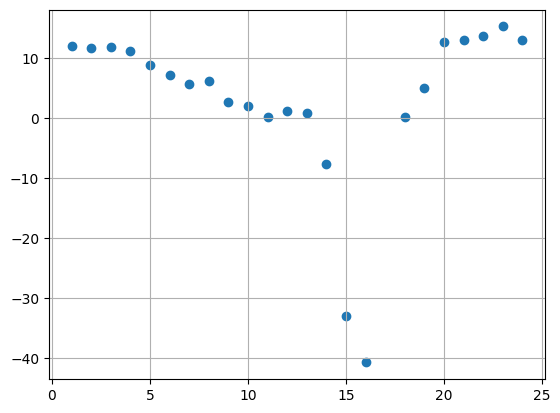

,Date,Hour,Volume,Price,P_Sell_low,P_Sell_upp
29821,2020-05-31,1.0,15067.600000,11.879692,11.80,11.9
29822,2020-05-31,2.0,14017.977215,11.604051,11.60,11.7
29823,2020-05-31,3.0,14261.880000,11.760364,11.70,11.8
29824,2020-05-31,4.0,16327.223810,11.090476,11.00,11.1
29825,2020-05-31,5.0,16571.600000,8.833182,8.80,8.9
29826,2020-05-31,6.0,16551.300000,7.151589,7.10,7.2
29827,2020-05-31,7.0,16815.800000,5.560788,5.50,5.6
29828,2020-05-31,8.0,16519.200000,6.121724,6.10,6.2
29829,2020-05-31,9.0,16342.700000,2.584000,2.50,2.6
29830,2020-05-31,10.0,14895.500000,2.000000,1.90,2.0


In [13]:
idx_test = 5

plt.scatter(Epex_Intersections[Epex_Intersections['Date']==peaks_dates[idx_test]]['Hour'].values,
            Epex_Intersections[Epex_Intersections['Date']==peaks_dates[idx_test]]['Price'].values)
plt.grid()
plt.show()

Epex_Intersections[Epex_Intersections['Date']==peaks_dates[idx_test]]

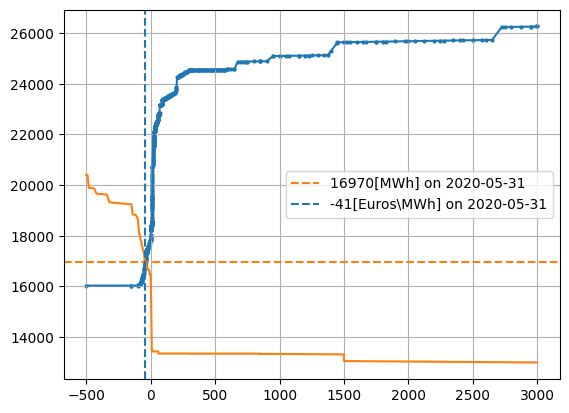

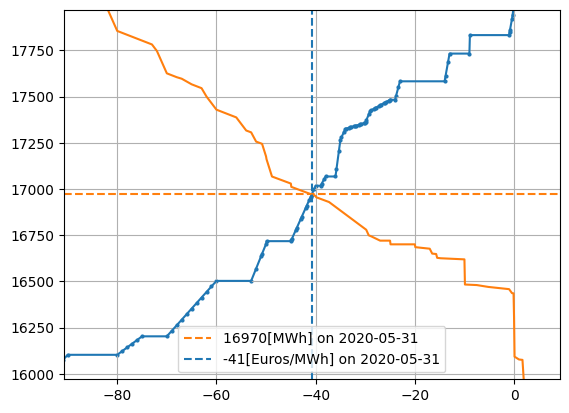

In [14]:
test_file = peaks_files[idx_test][peaks_files[idx_test]['Hour']==peaks_dates_hour[idx_test]].copy()

test_file_sells = test_file[test_file['Sale/Purchase'] == 'Sell'].copy()
test_file_purchases = test_file[test_file['Sale/Purchase'] == 'Purchase'].copy()

plt.scatter(test_file_sells['Price'].values, test_file_sells['Volume'].values, s=4)
plt.plot(test_file_sells['Price'].values, test_file_sells['Volume'].values)
plt.plot(test_file_purchases['Price'].values, test_file_purchases['Volume'].values)

plt.axhline(y=peaks_intersec_files[idx_test]['Volume'], linestyle='--', color='tab:orange', label=f"{peaks_intersec_files[idx_test]['Volume']:.0f}[MWh] on {str(peaks_dates[idx_test].date())}")
plt.axvline(x=peaks_intersec_files[idx_test]['Price'], linestyle='--', label=f"{peaks_intersec_files[idx_test]['Price']:.0f}[Euros\MWh] on {str(peaks_dates[idx_test].date())}")

plt.legend()
plt.grid()
plt.show()

plt.scatter(test_file_sells['Price'].values, test_file_sells['Volume'].values, s=4)
plt.plot(test_file_sells['Price'].values, test_file_sells['Volume'].values)
plt.plot(test_file_purchases['Price'].values, test_file_purchases['Volume'].values)

plt.axhline(y=peaks_intersec_files[idx_test]['Volume'], linestyle='--', color='tab:orange', label=f"{peaks_intersec_files[idx_test]['Volume']:.0f}[MWh] on {str(peaks_dates[idx_test].date())}")
plt.axvline(x=peaks_intersec_files[idx_test]['Price'], linestyle='--', label=f"{peaks_intersec_files[idx_test]['Price']:.0f}[Euros/MWh] on {str(peaks_dates[idx_test].date())}")

plt.legend()
plt.grid()
plt.ylim([peaks_intersec_files[idx_test]['Volume'] - 1000, peaks_intersec_files[idx_test]['Volume'] + 1000])
plt.xlim([peaks_intersec_files[idx_test]['Price']-50,peaks_intersec_files[idx_test]['Price']+50])

plt.show()

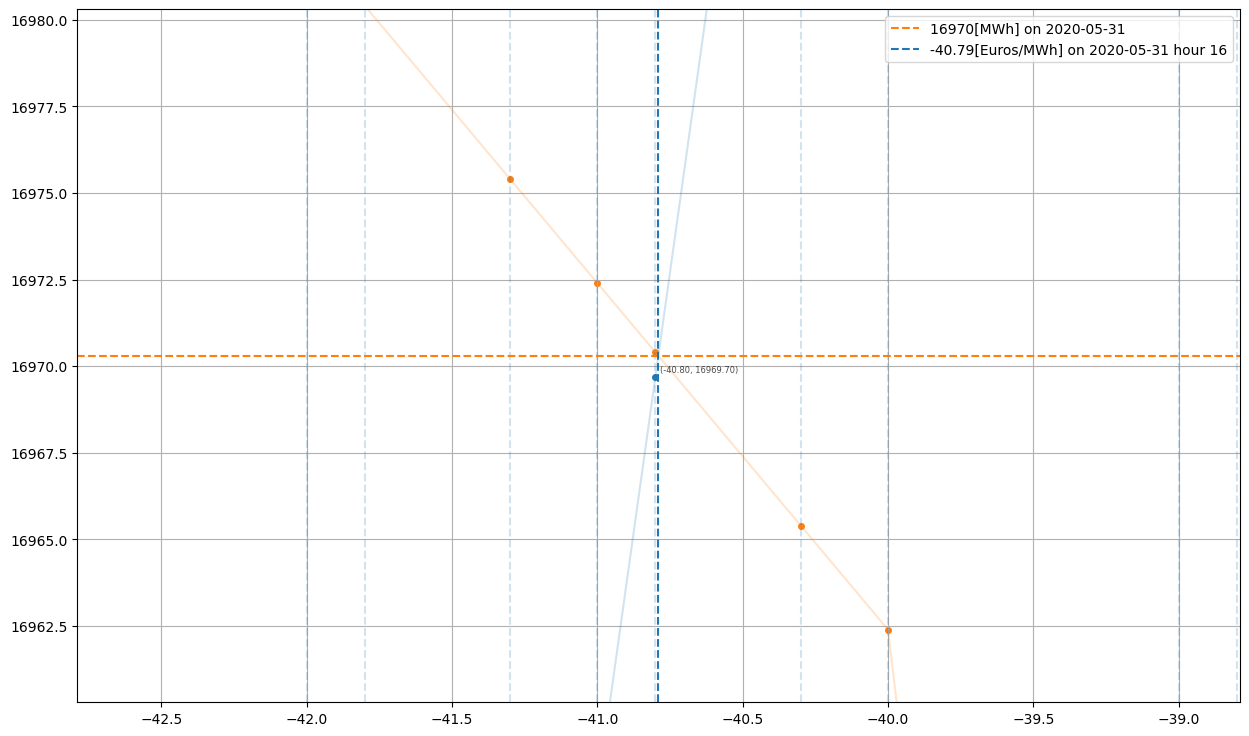

In [15]:
test_file = peaks_files[idx_test][peaks_files[idx_test]['Hour']==peaks_dates_hour[idx_test]].copy()

test_file_sells = test_file[test_file['Sale/Purchase'] == 'Sell'].copy()
test_file_purchases = test_file[test_file['Sale/Purchase'] == 'Purchase'].copy()

plt.figure(figsize=(15, 9))

plt.scatter(test_file_sells['Price'].values, test_file_sells['Volume'].values, s=16)
plt.plot(test_file_sells['Price'].values, test_file_sells['Volume'].values, alpha=0.2)

for value in test_file_sells['Price'].values:
  plt.axvline(x=value, linestyle='--', alpha=0.2)

for x, y in zip(test_file_sells['Price'], test_file_sells['Volume']):
    plt.annotate(
        f"({x:.2f}, {y:.2f})",        # text to display
        (x, y),                     # point to label
        textcoords="offset points", # how to position text
        xytext=(3, 3),              # offset (x,y) in points
        fontsize=6,                 # smaller font
        alpha=0.7
    )

plt.scatter(test_file_purchases['Price'].values, test_file_purchases['Volume'].values, s=16)
plt.plot(test_file_purchases['Price'].values, test_file_purchases['Volume'].values, alpha=0.2)

plt.axhline(y=peaks_intersec_files[idx_test]['Volume'], linestyle='--', color='tab:orange', label=f"{peaks_intersec_files[idx_test]['Volume']:.0f}[MWh] on {str(peaks_dates[idx_test].date())}")
plt.axvline(x=peaks_intersec_files[idx_test]['Price'], linestyle='--', label=f"{peaks_intersec_files[idx_test]['Price']:.2f}[Euros/MWh] on {str(peaks_dates[idx_test].date())} hour {peaks_dates_hour[idx_test]}")

plt.legend()
plt.grid()
plt.ylim([peaks_intersec_files[idx_test]['Volume'] - 10, peaks_intersec_files[idx_test]['Volume'] + 10]) #70
plt.xlim([peaks_intersec_files[idx_test]['Price']-2,peaks_intersec_files[idx_test]['Price']+2])

plt.show()

In [16]:
full_test_file = peaks_files[idx_test].copy()
full_test_file['Date']=pd.to_datetime(full_test_file['Date'], format="%d/%m/%Y")
full_test_file_sells = full_test_file[full_test_file['Sale/Purchase'] == 'Sell'].copy()
full_test_file_purchases = full_test_file[full_test_file['Sale/Purchase'] == 'Purchase'].copy()


full_test_file_sells.sort_values(by=['Hour', 'Price'], inplace=True)

full_test_file_sells['DVolume'] = (
    full_test_file_sells
      .groupby('Hour')['Volume']
      .diff().fillna(full_test_file_sells['Volume']).round(1)
)

full_test_file_sells['DPrice'] = (
    full_test_file_sells
      .groupby('Hour')['Price']
      .diff().fillna(full_test_file_sells['Price']).round(1)
)

#DVolume modeling

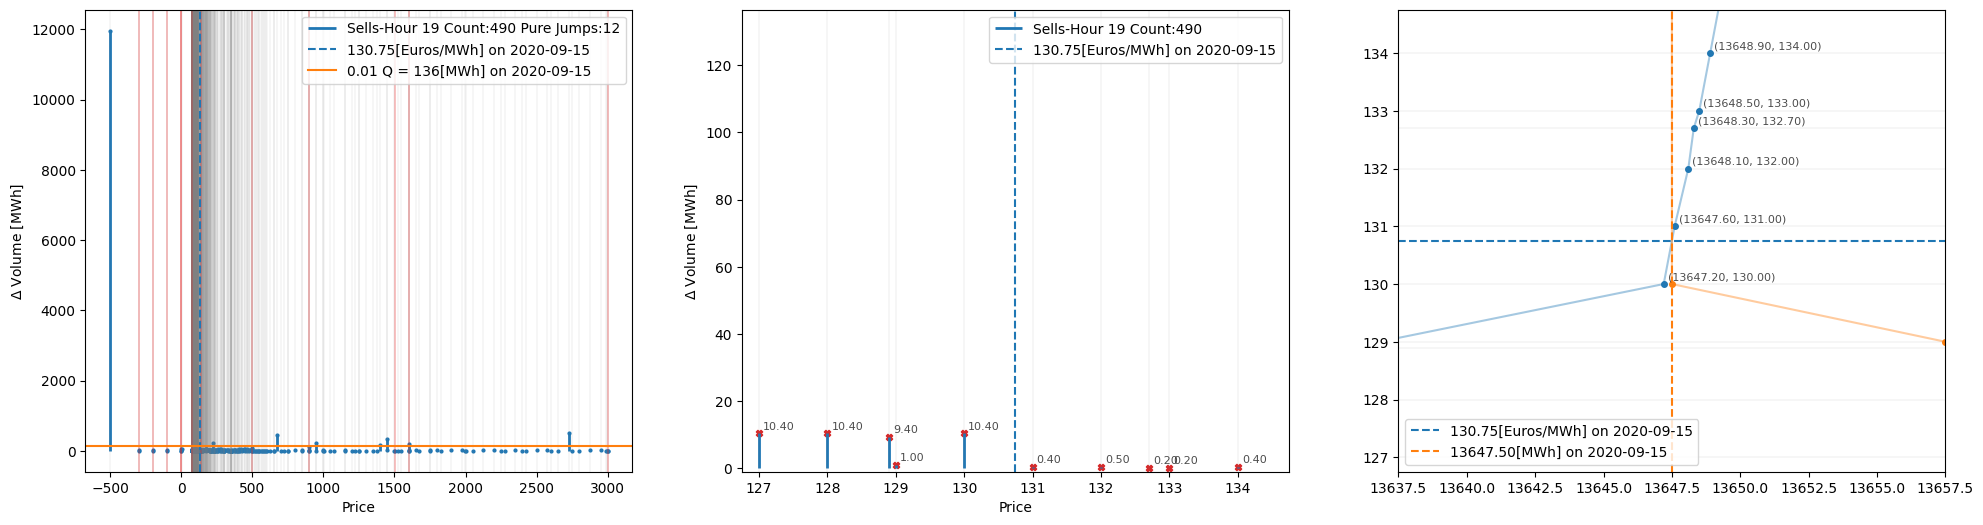

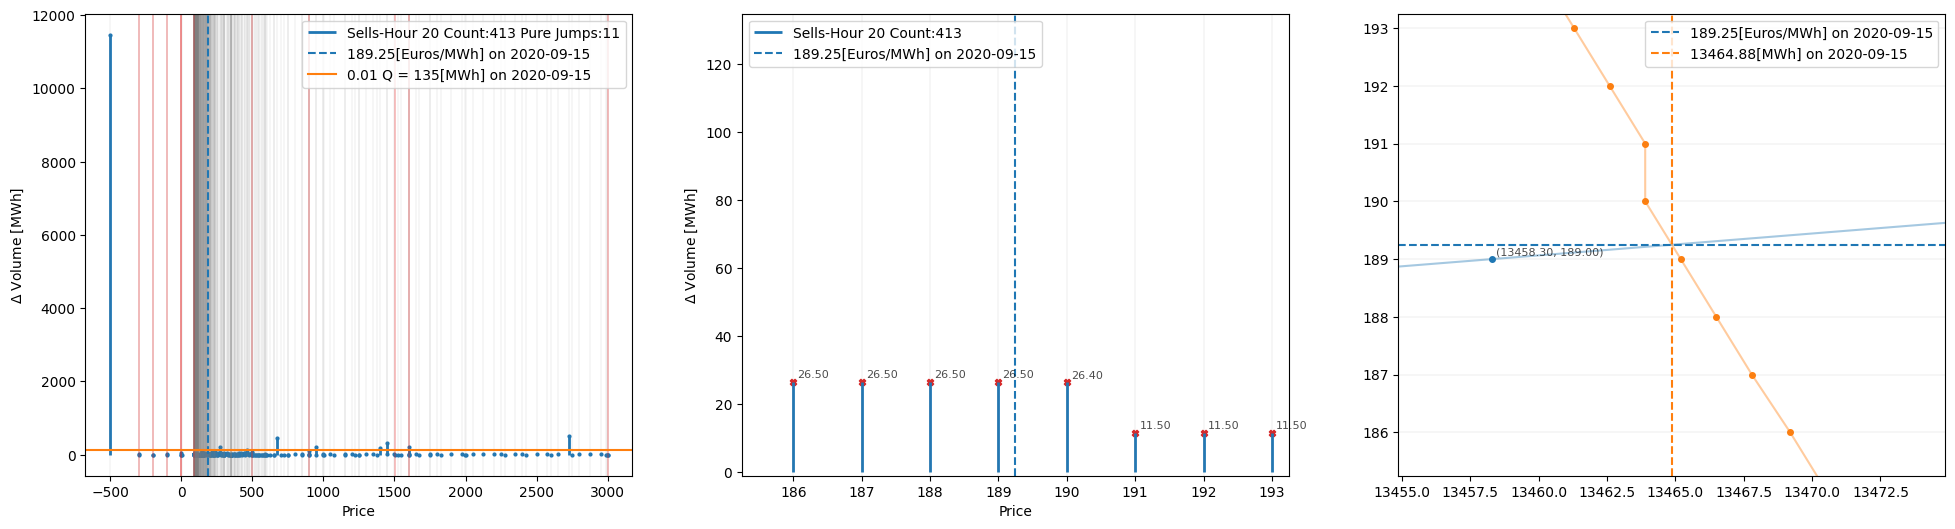

In [ ]:
for hour in [19,20]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells[full_test_file_sells['Hour'] == hour].copy()
  Sells_0 = Sells[Sells['DVolume']==0]

  Purchases = full_test_file_purchases[full_test_file_purchases['Hour'] == hour].copy()

  Date_ = Sells['Date'].iloc[0]
  Price_ = Epex_Intersections[(Epex_Intersections['Date']==Date_)&(Epex_Intersections['Hour']==hour)]['Price'].values[0]
  Volume_ = Epex_Intersections[(Epex_Intersections['Date']==Date_)&(Epex_Intersections['Hour']==hour)]['Volume'].values[0]


  fig, ax = plt.subplots(1,3, figsize=(24, 6))

  ax[0].vlines(x=Sells['Price'], ymin=0, ymax=Sells['DVolume'], linewidth=2, alpha=1, label=f'Sells-Hour {hour} Count:{Sells.shape[0]} Pure Jumps:{Sells_0.shape[0]}', color='C0')
  ax[1].vlines(x=Sells['Price'], ymin=0, ymax=Sells['DVolume'], linewidth=2, alpha=1, label=f'Sells-Hour {hour} Count:{Sells.shape[0]}', color='C0')

  ax[0].scatter(Sells['Price'], Sells['DVolume'], marker='o', color='C0', s=4)
  ax[1].scatter(Sells['Price'], Sells['DVolume'], marker='X', color='C3', s=20)
  for x, y in zip(Sells['Price'], Sells['DVolume']):
    ax[1].annotate(
        f"{y:.2f}",        # text to display
        (x, y),                     # point to label
        textcoords="offset points", # how to position text
        xytext=(3, 3),              # offset (x,y) in points
        fontsize=8,                 # smaller font
        alpha=0.7
    )

  ax[0].set_xlabel('Price')
  ax[1].set_xlabel('Price')
  ax[0].set_ylabel('$\Delta$ Volume [MWh]')
  ax[1].set_ylabel('$\Delta$ Volume [MWh]')

  for value in Sells['Price']:
    ax[0].axvline(x=value, linestyle='-', linewidth=0.1, color = 'gray', alpha=1)
    ax[1].axvline(x=value, linestyle='-', linewidth=0.1, color = 'gray', alpha=1)
    ax[2].axhline(y=value, linestyle='-', linewidth=0.1, color = 'gray', alpha=1)

  for value in Sells_0['Price']:
    ax[0].axvline(x=value, linestyle='-', linewidth=0.3, color = 'red', alpha=1)
    ax[1].axvline(x=value, linestyle='-', linewidth=0.3, color = 'red', alpha=1)
    ax[2].axhline(y=value, linestyle='-', linewidth=0.3, color = 'red', alpha=1)

  ax[2].scatter(Sells['Volume'].values, Sells['Price'].values, s=16)
  ax[2].plot(Sells['Volume'].values, Sells['Price'].values, alpha=0.4)
  for x, y in zip(Sells['Volume'], Sells['Price']):
    ax[2].annotate(
        f"({x:.2f}, {y:.2f})",        # text to display
        (x, y),                     # point to label
        textcoords="offset points", # how to position text
        xytext=(3, 3),              # offset (x,y) in points
        fontsize=8,                 # smaller font
        alpha=0.7
    )
  ax[2].scatter(Purchases['Volume'].values, Purchases['Price'].values, s=16)
  ax[2].plot(Purchases['Volume'].values, Purchases['Price'].values, alpha=0.4)

  ax[0].axvline(x=Price_, linestyle='--', label=f"{Price_:.2f}[Euros/MWh] on {str(peaks_dates[idx_test].date())}")
  ax[0].axhline(y=Volume_/100, linestyle='-', color='tab:orange', label=f"0.01 Q = {Volume_/100:.0f}[MWh] on {str(peaks_dates[idx_test].date())}")
  ax[1].axvline(x=Price_, linestyle='--', label=f"{Price_:.2f}[Euros/MWh] on {str(peaks_dates[idx_test].date())}")
  ax[2].axhline(y=Price_, linestyle='--', label=f"{Price_:.2f}[Euros/MWh] on {str(peaks_dates[idx_test].date())}")
  ax[2].axvline(x=Volume_, linestyle='--', color='tab:orange', label=f"{Volume_:.2f}[MWh] on {str(peaks_dates[idx_test].date())}")

  ax[0].legend()
  ax[1].legend()
  ax[2].legend()

  #ax[1].set_xlim([peaks_intersec_files[idx_test]['Price']-100,peaks_intersec_files[idx_test]['Price']+100])
  ax[1].set_xlim([Price_-4,Price_+4])   #  ax[1].set_xlim([-510,10])
  ax[2].set_ylim([Price_-4,Price_+4])   #  ax[2].set_xlim([-510,10])
  ax[1].set_ylim([-1,Volume_/100])
  ax[2].set_xlim([Volume_-10,Volume_+10])

  plt.show()

In [17]:
max_power = 8
#bins=np.concatenate(([0],10**np.array([i for i in range(max_power)])))
bins=np.array([0, 1, 10, 10**2, 10**3, 10**6])
print(bins)

bins_keys=[i for i in range(-1,len(bins)-1)]
DVolume_dict={}
DVolume_dict[-1]=full_test_file_sells[full_test_file_sells['DVolume']==0].copy()

for bin in bins_keys[1:]:
  DVolume_dict[bin]=full_test_file_sells[full_test_file_sells['DVolume'].between(bins[bin], bins[bin+1], inclusive='right')].copy()
  print(bins[bin], bins[bin+1])


for bin in bins_keys:
  print(f"{bin}: {DVolume_dict[bin].shape[0]}, Price range: {DVolume_dict[bin]['Price'].min()},{DVolume_dict[bin]['Price'].max()}")

[      0       1      10     100    1000 1000000]
0 1
1 10
10 100
100 1000
1000 1000000
-1: 719, Price range: -150.1,3000.0
0: 2708, Price range: -150.0,2999.9
1: 5825, Price range: -100.0,2990.0
2: 5339, Price range: -124.0,319.9
3: 410, Price range: -35.3,2725.0
4: 25, Price range: -500.0,10.5


In [18]:
aggregate_DVol_byPrice=[]
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells[full_test_file_sells['Hour'] == hour].copy()
  temp_ = aggregate_by_grid(np.arange(-500, 3000, 5),
                  Sells['Price'].values[1:], Sells['DVolume'][1:].values)
  temp_['Hour']=hour
  temp_['Date']=Sells['Date'].iloc[0]
  aggregate_DVol_byPrice.append(temp_)
aggregate_DVol_byPrice_main = pd.concat(aggregate_DVol_byPrice)


aggregate_DVol_byPrice = aggregate_DVol_byPrice_main.pivot(index='Hour', columns='x', values='y_sum')
aggregate_DVol_byPrice['Date']=Sells['Date'].iloc[0]
aggregate_DVol_byPrice.reset_index(inplace=True)

Date_ = Sells['Date'].iloc[0]
Price_ = Epex_Intersections[(Epex_Intersections['Date']==Date_)][['Price','Hour']].values
Volume_ = Epex_Intersections[(Epex_Intersections['Date']==Date_)][['Volume','Hour']].values

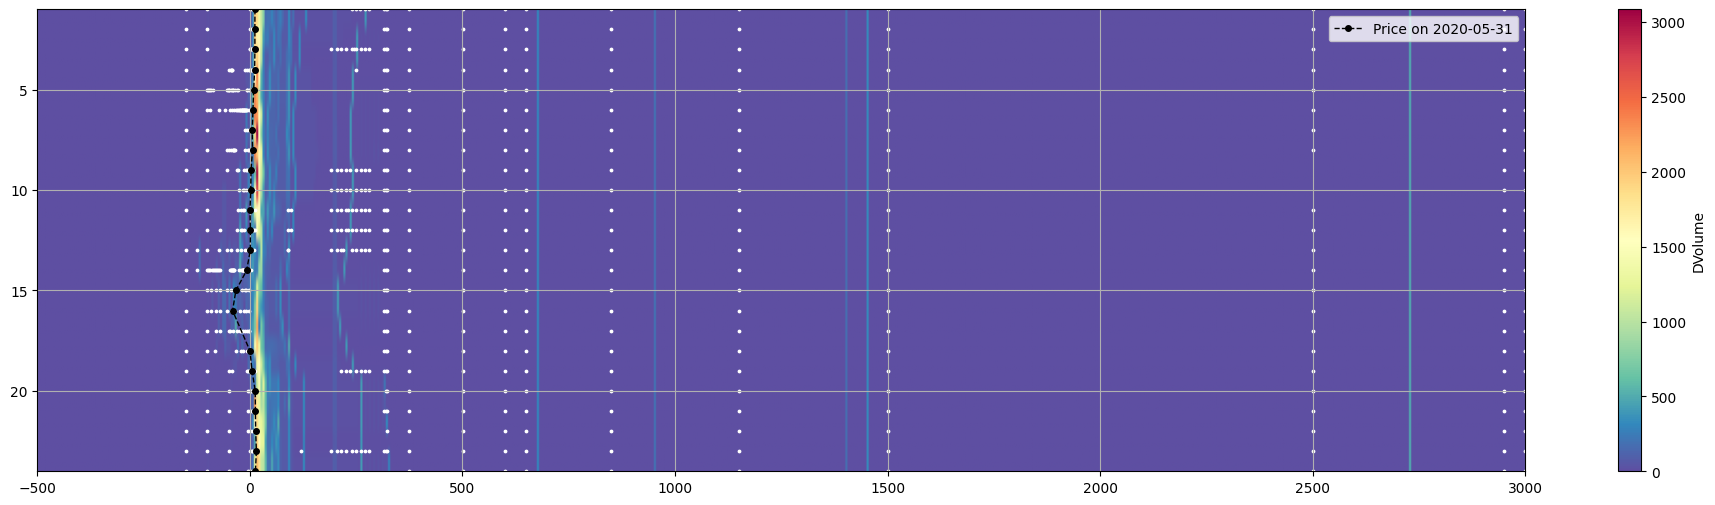

In [19]:
fig, ax = plt.subplots(1,1, figsize=(24, 6))
im = ax.imshow(aggregate_DVol_byPrice.values[:,1:-1].astype(float), aspect='auto', origin='upper',
           cmap='Spectral_r', extent=[-500, 3000, 24, 1] #on y it is lower, upper
           )
fig.colorbar(im, ax=ax, label='DVolume', orientation='vertical')
plt.grid()
ax.plot(Price_[:,0], Price_[:,1], color='black', linestyle='--', marker='o', markersize=4, linewidth=1, label=f'Price on {str(Date_.date())}')

for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  values_temp = DVolume_dict[-1][DVolume_dict[-1]['Hour']==hour]['Price'].values
  plt.scatter(values_temp, hour*np.ones_like(values_temp), color='white', s=3)
plt.legend()
plt.show()

In [20]:
bins_colors=['purple', 'blue', 'green', 'yellow', 'orange', 'red', 'red', 'red', 'red']

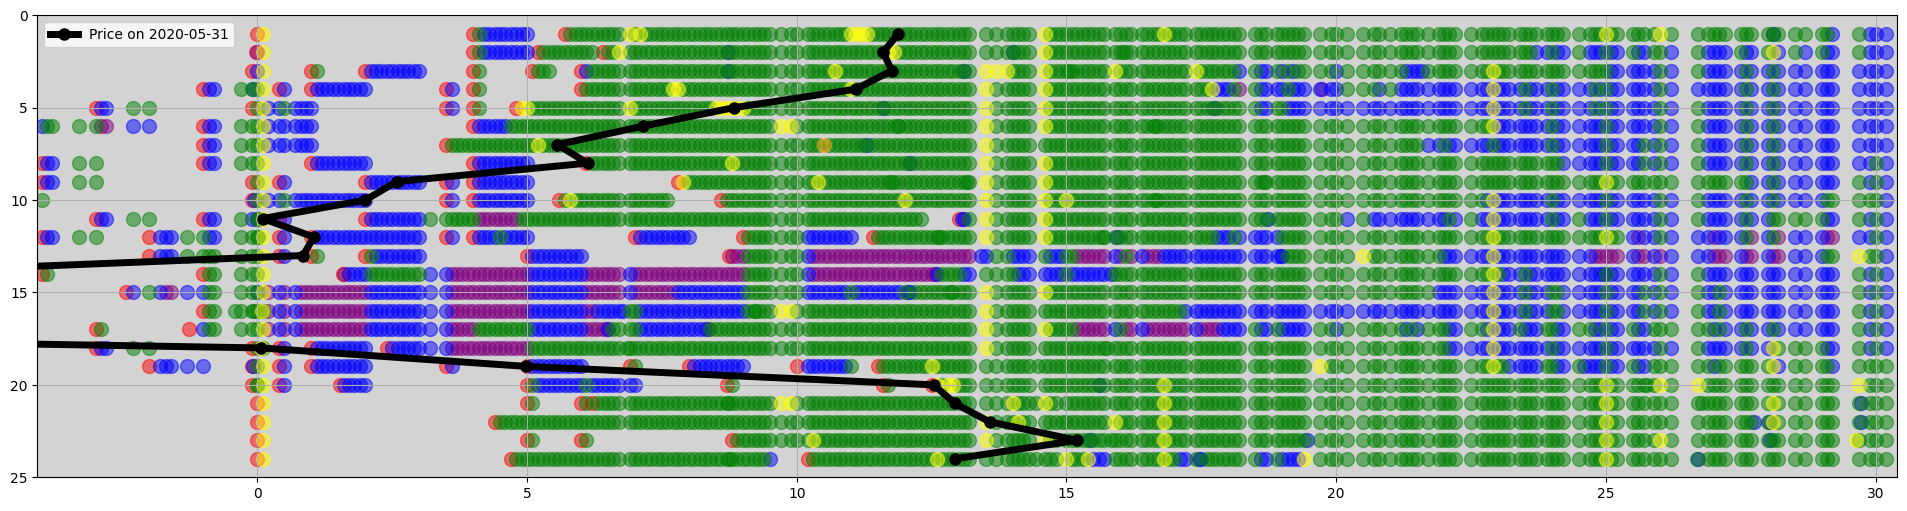

In [21]:
fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  for bin in bins_keys:
    values_temp = DVolume_dict[bin][DVolume_dict[bin]['Hour']==hour]['Price'].values
    plt.scatter(values_temp, hour*np.ones_like(values_temp), color=bins_colors[bin], s=100, alpha=0.5)
plt.xlim([Price_[:,0].min()*0.1,Price_[:,0].max()*2])
plt.ylim([0,25])
ax.yaxis.set_inverted(True)
ax.set_facecolor('lightgray')


ax.plot(Price_[:,0], Price_[:,1], color='black', linestyle='-', marker='o', markersize=8, linewidth=5, label=f'Price on {str(Date_.date())}')
#plt.axvline(x=20, linestyle='-', linewidth=2, color = 'white', alpha=1)
#plt.axvline(x=80, linestyle='-', linewidth=2, color = 'white', alpha=1)
plt.legend()
#plt.xlim([-20,50])
plt.show()

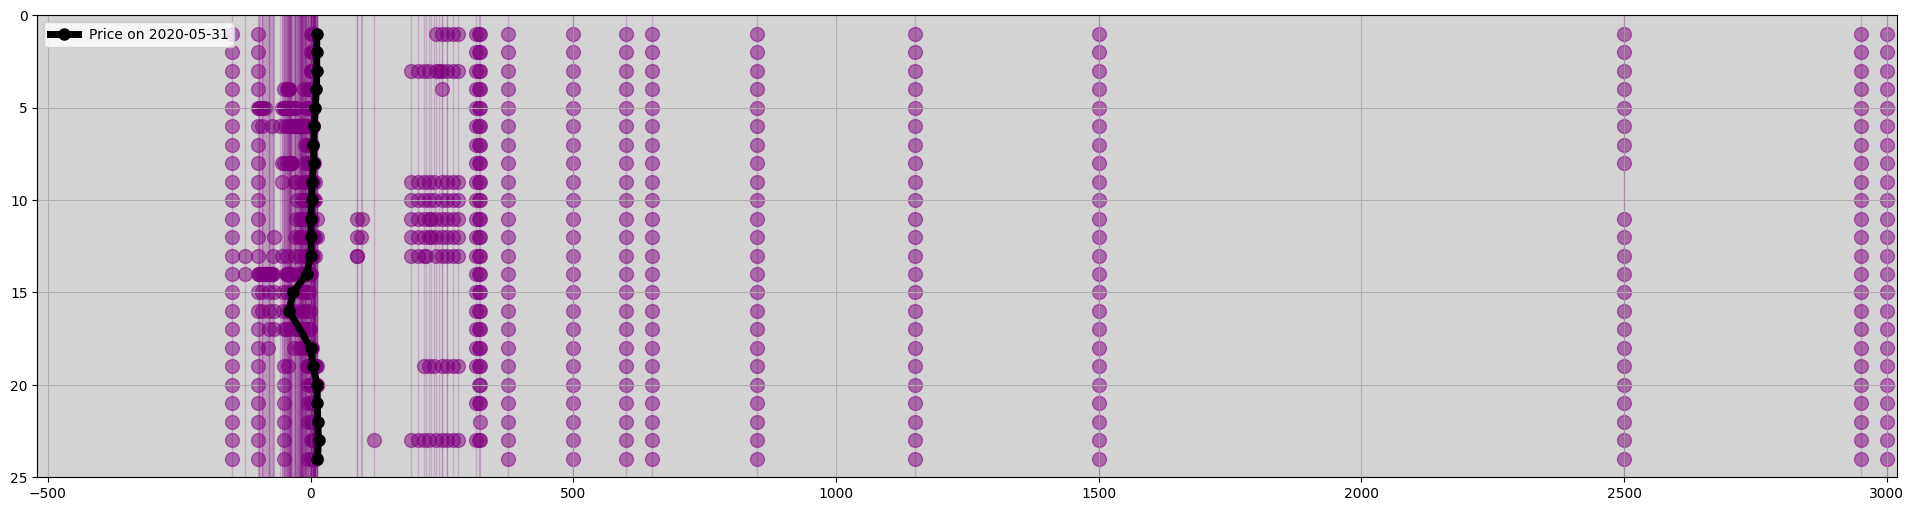

In [22]:
fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  values_temp = DVolume_dict[-1][DVolume_dict[-1]['Hour']==hour]['Price'].values
  plt.scatter(values_temp, hour*np.ones_like(values_temp), color='purple', s=100, alpha=0.5)
plt.xlim([-500-20,3000+20])
plt.ylim([0,25])
ax.yaxis.set_inverted(True)
ax.set_facecolor('lightgray')

for value in DVolume_dict[-1]['Price'].unique():
  plt.axvline(x=value, linestyle='-', linewidth=1, color = 'purple', alpha=0.2)

ax.plot(Price_[:,0], Price_[:,1], color='black', linestyle='-', marker='o', markersize=8, linewidth=5, label=f'Price on {str(Date_.date())}')
#plt.axvline(x=20, linestyle='-', linewidth=2, color = 'white', alpha=1)
#plt.axvline(x=80, linestyle='-', linewidth=2, color = 'white', alpha=1)
plt.legend()
plt.show()

#Model for the $\Delta Q=0$ (pure price jumps) arrivals

In [23]:
t_arrDV_dict = {}
for bin in bins_keys:
  t_arrDV_dict[bin] = DVolume_dict[bin]['Price'].unique()
  t_arrDV_dict[bin] = np.sort(t_arrDV_dict[bin])
  t_arrDV_dict[bin] = (t_arrDV_dict[bin] + 500)/3500

In [24]:
edges = np.concatenate([np.linspace(0,0.1,5)[:-1], np.linspace(0.1,0.2,10), np.linspace(0.2,1,5)[1:]])
grid = np.linspace(0,1,1000)
Price_QN = (Price_[:,0]+500)/3500

In [25]:
t_arrDV_models_dict={}
for bin in bins_keys:
  t_arrDV_models_dict[bin]=GridNHPP(edges)
  t_arrDV_models_dict[bin].fit(t_arrDV_dict[bin])
  print('Convergence of ML estimation:', t_arrDV_models_dict[bin].flag)

AttributeError: 'GridNHPP' object has no attribute 'T'

In [ ]:
for bin in bins_keys:
  t_arrDV_models_dict[bin].lam = t_arrDV_models_dict[bin].predict(grid)
  plt.plot(grid, t_arrDV_models_dict[bin].lam, '--', label='$\hat{\lambda}$')
  plt.axhline(0, color='r', lw=2)
  plt.legend()
  plt.show()
  t_arrDV_models_dict[bin].goodness_of_fit(t_arrDV_dict[bin])

In [ ]:
for bin in bins_keys:
  t_arrDV_models_dict[bin].sample = t_arrDV_models_dict[bin].simulate()

  plt.figure(figsize=(10, 4))
  plt.plot(grid, t_arrDV_models_dict[bin].lam, '--', label='$\hat{\lambda}$')

  plt.vlines(t_arrDV_models_dict[bin].sample, ymin=0, ymax=-np.max(t_arrDV_models_dict[bin].lam)*0.1, color='C0', alpha=0.3,
             linestyle='-', label='Events sim')
  plt.vlines(t_arrDV_dict[bin], ymin=-np.max(t_arrDV_models_dict[bin].lam)*0.1, ymax=-2*np.max(t_arrDV_models_dict[bin].lam)*0.1, color='C1', alpha=0.3,
             linestyle='-', label='Events real')

  plt.scatter(Price_QN, -2*np.max(t_arrDV_models_dict[bin].lam)*0.1*np.ones_like(Price_QN), color='black', s=50)
  plt.ylabel('Intensity $\lambda(t)$')
  plt.title(f'Fitted non-homogeneous Poisson Process Intensity (Piece-wise linear) DV-{bin}')
  plt.legend(loc='upper right')
  plt.tight_layout()
  plt.show()


  plt.figure(figsize=(10, 4))
  plt.plot(grid, t_arrDV_models_dict[bin].lam, '--', label='$\hat{\lambda}$')

  plt.vlines(t_arrDV_models_dict[bin].sample, ymin=0, ymax=-np.max(t_arrDV_models_dict[bin].lam)*0.1, color='C0', alpha=0.3,
           linestyle='-', label='Events sim')
  plt.vlines(t_arrDV_dict[bin], ymin=-np.max(t_arrDV_models_dict[bin].lam)*0.1, ymax=-2*np.max(t_arrDV_models_dict[bin].lam)*0.1, color='C1', alpha=0.3,
           linestyle='-', label='Events real')

  plt.scatter(Price_QN, -2*np.max(t_arrDV_models_dict[bin].lam)*0.1*np.ones_like(Price_QN), color='black', s=50)
  plt.ylabel('Intensity $\lambda(t)$')
  plt.title(f'Fitted non-homogeneous Poisson Process Intensity (Piece-wise linear) DV-{bin}')
  plt.legend(loc='upper right')
  plt.tight_layout()
  plt.xlim([np.max(Price_QN)*0.2, np.max(Price_QN)*1.2])
  plt.show()


#Continue

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  values_temp = DVolume_dict[0][DVolume_dict[0]['Hour']==hour]['Price'].values
  plt.scatter(values_temp, hour*np.ones_like(values_temp), color='blue', s=100, alpha=0.5)

ax.plot(Price_[:,0], Price_[:,1], color='black', linestyle='-', marker='o', markersize=8, linewidth=5, label=f'Price on {str(Date_.date())}')

plt.xlim([-500-20,3000+20])
plt.ylim([0,25])
ax.yaxis.set_inverted(True)
ax.set_facecolor('lightgray')
plt.legend()
plt.show()

In [ ]:
# prompt: Draw a histogram of "DVolume_dict[0]['DVolume']"

plt.figure()
plt.hist(DVolume_dict[0]['DVolume'])
plt.xlabel("DVolume")
plt.ylabel("Frequency")
plt.title("Histogram of DVolume for DVolume_dict[0]")
plt.show()


In [ ]:
fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  values_temp = DVolume_dict[1][DVolume_dict[1]['Hour']==hour]['Price'].values
  plt.scatter(values_temp, hour*np.ones_like(values_temp), color='green', s=100, alpha=0.5)
ax.plot(Price_[:,0], Price_[:,1], color='black', linestyle='-', marker='o', markersize=8, linewidth=5, label=f'Price on {str(Date_.date())}')
plt.xlim([-500-20,3000+20])
plt.ylim([0,25])
ax.yaxis.set_inverted(True)
ax.set_facecolor('lightgray')
plt.show()

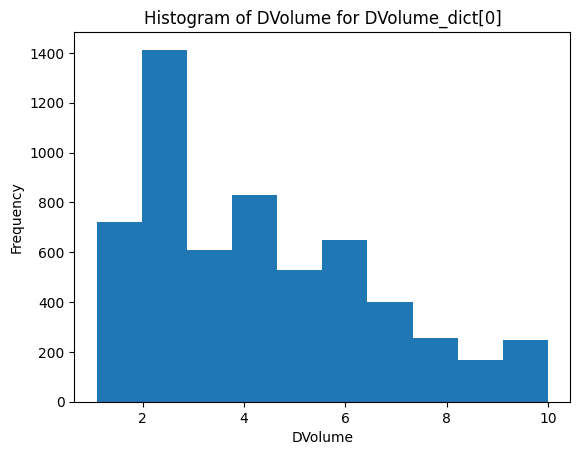

In [ ]:
plt.figure()
plt.hist(DVolume_dict[1]['DVolume'])
plt.xlabel("DVolume")
plt.ylabel("Frequency")
plt.title("Histogram of DVolume for DVolume_dict[0]")
plt.show()


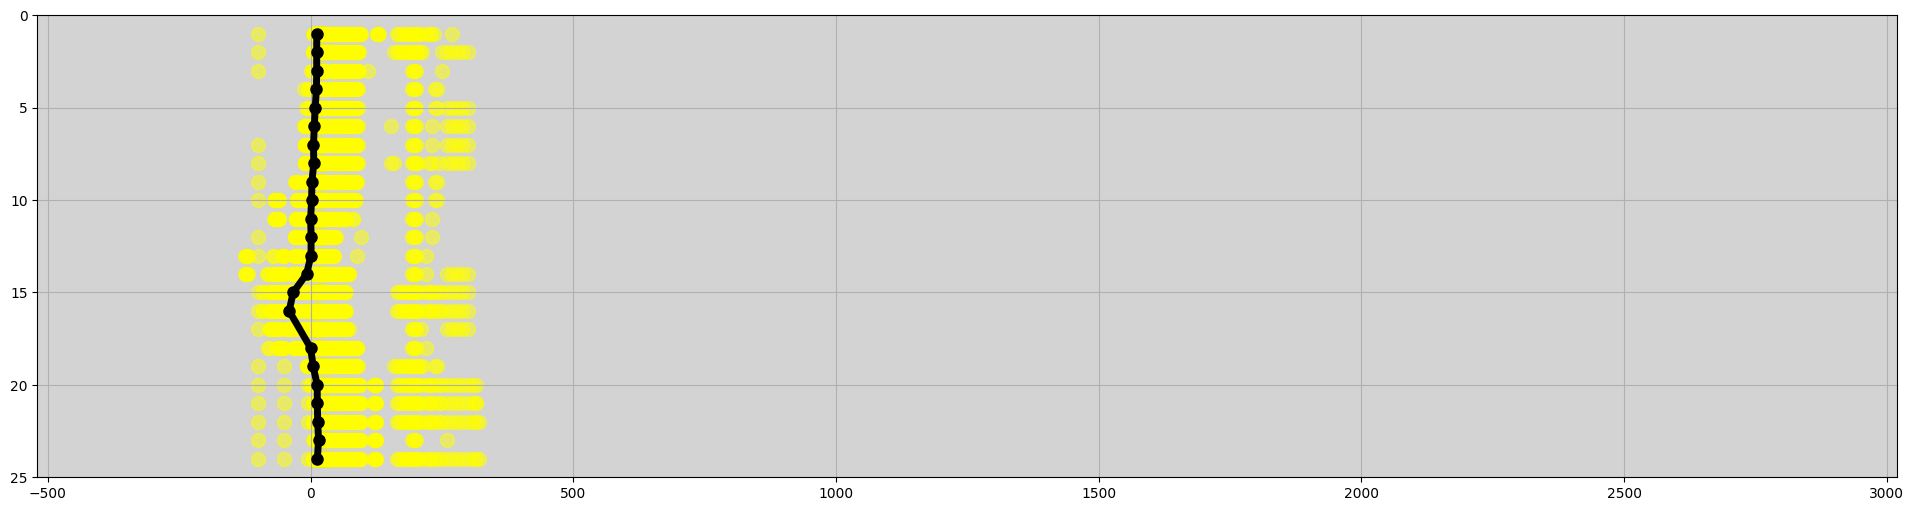

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  values_temp = DVolume_dict[2][DVolume_dict[2]['Hour']==hour]['Price'].values
  plt.scatter(values_temp, hour*np.ones_like(values_temp), color='yellow', s=100, alpha=0.5)
ax.plot(Price_[:,0], Price_[:,1], color='black', linestyle='-', marker='o', markersize=8, linewidth=5, label=f'Price on {str(Date_.date())}')
plt.xlim([-500-20,3000+20])
plt.ylim([0,25])
ax.yaxis.set_inverted(True)
ax.set_facecolor('lightgray')
plt.show()

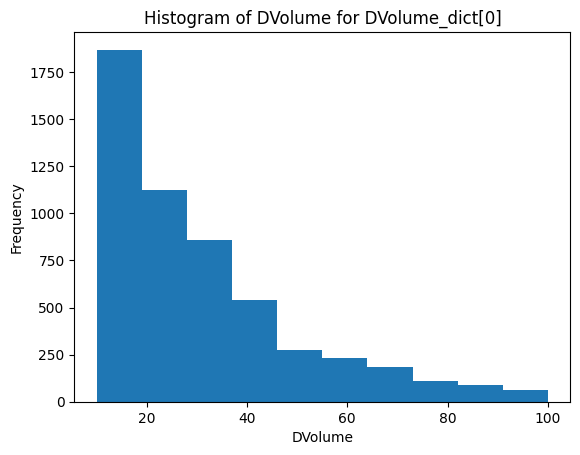

In [ ]:
plt.figure()
plt.hist(DVolume_dict[2]['DVolume'])
plt.xlabel("DVolume")
plt.ylabel("Frequency")
plt.title("Histogram of DVolume for DVolume_dict[0]")
plt.show()

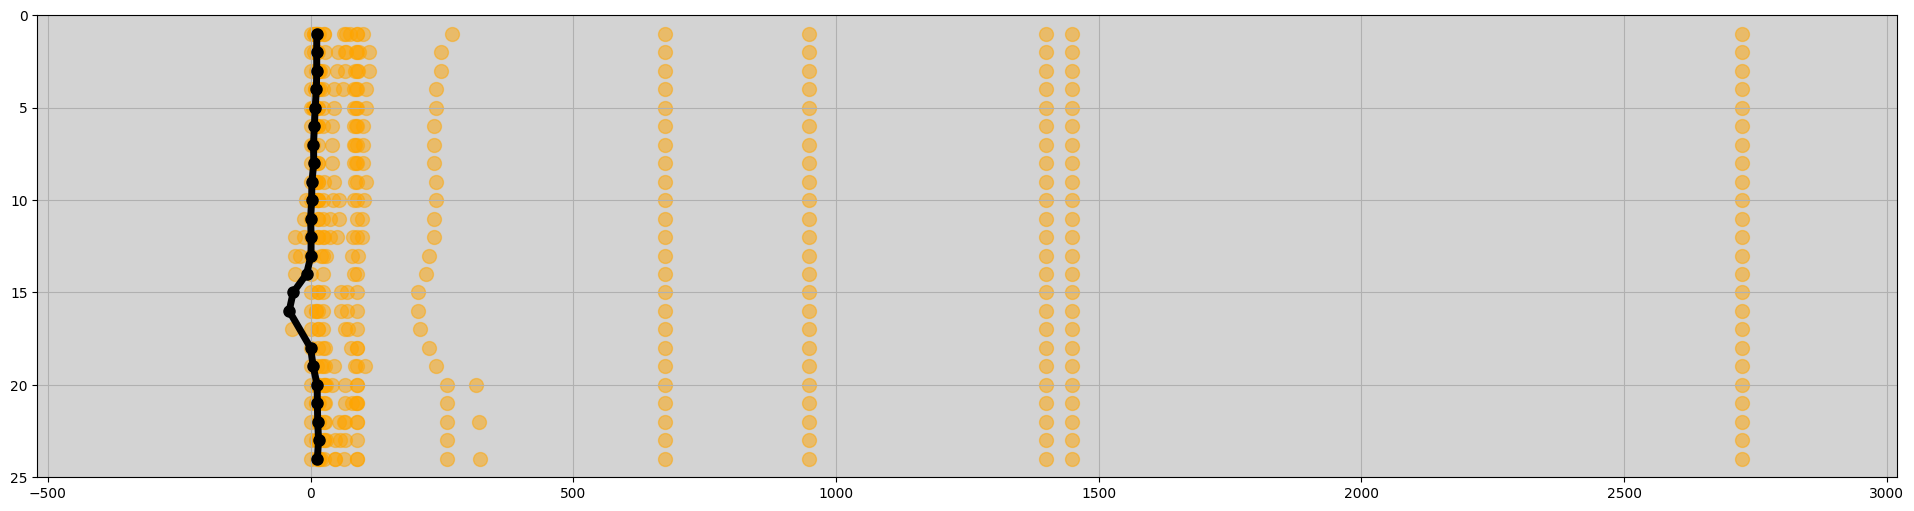

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  values_temp = DVolume_dict[3][DVolume_dict[3]['Hour']==hour]['Price'].values
  plt.scatter(values_temp, hour*np.ones_like(values_temp), color='orange', s=100, alpha=0.5)
ax.plot(Price_[:,0], Price_[:,1], color='black', linestyle='-', marker='o', markersize=8, linewidth=5, label=f'Price on {str(Date_.date())}')
plt.xlim([-500-20,3000+20])
plt.ylim([0,25])
ax.yaxis.set_inverted(True)
ax.set_facecolor('lightgray')
plt.show()

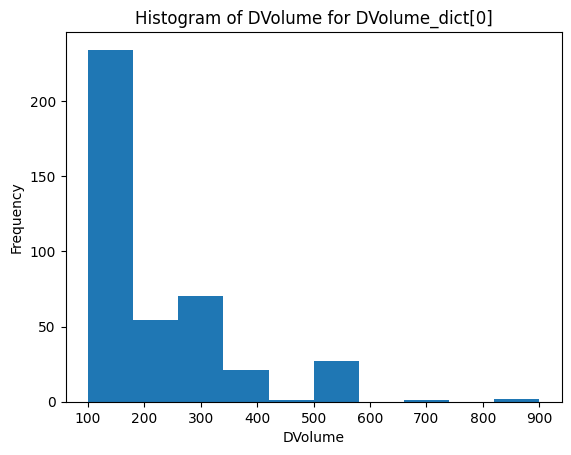

In [ ]:
plt.figure()
plt.hist(DVolume_dict[3]['DVolume'])
plt.xlabel("DVolume")
plt.ylabel("Frequency")
plt.title("Histogram of DVolume for DVolume_dict[0]")
plt.show()

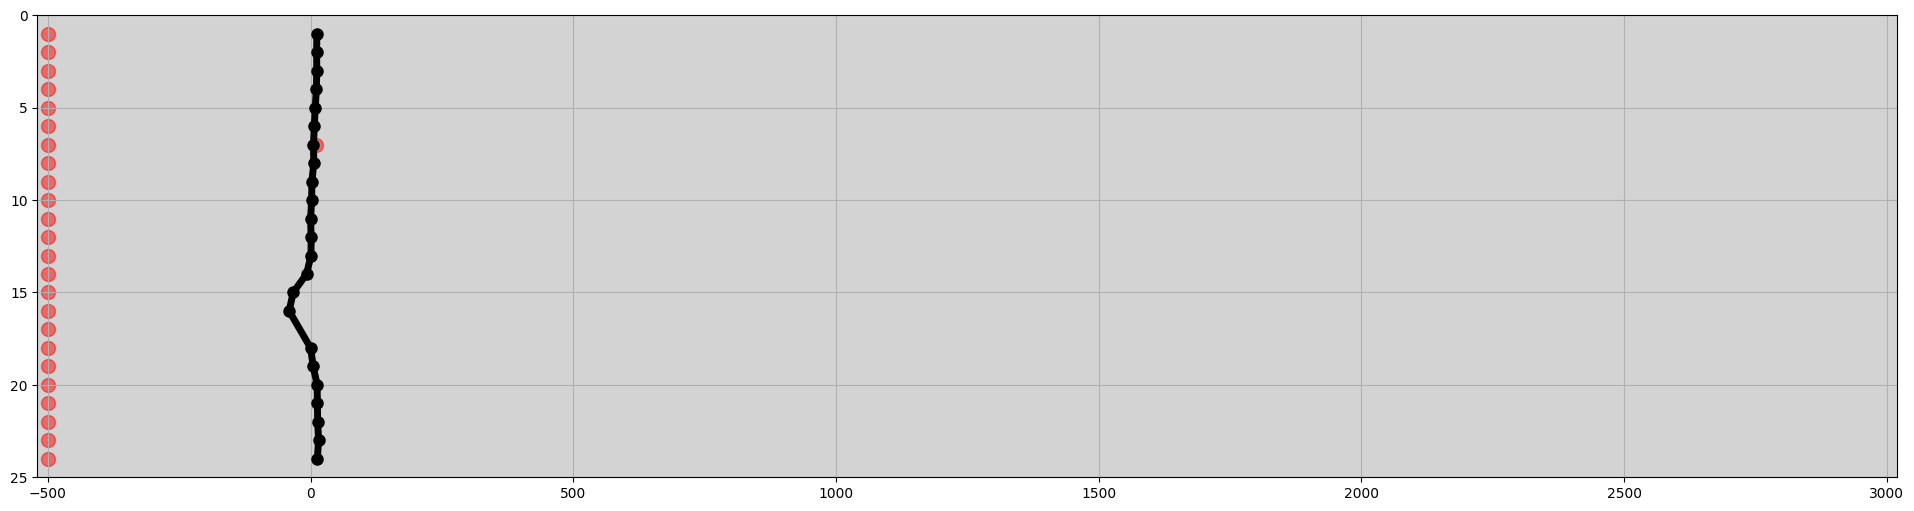

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  values_temp = DVolume_dict[4][DVolume_dict[4]['Hour']==hour]['Price'].values
  plt.scatter(values_temp, hour*np.ones_like(values_temp), color='red', s=100, alpha=0.5)
ax.plot(Price_[:,0], Price_[:,1], color='black', linestyle='-', marker='o', markersize=8, linewidth=5, label=f'Price on {str(Date_.date())}')
plt.xlim([-500-20,3000+20])
plt.ylim([0,25])
ax.yaxis.set_inverted(True)
ax.set_facecolor('lightgray')
plt.show()

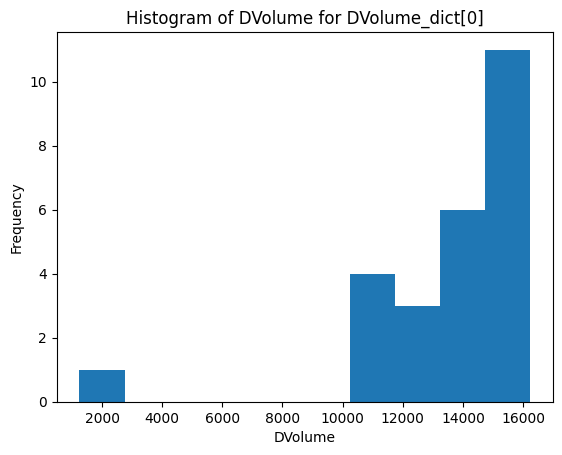

In [ ]:
plt.figure()
plt.hist(DVolume_dict[4]['DVolume'])
plt.xlabel("DVolume")
plt.ylabel("Frequency")
plt.title("Histogram of DVolume for DVolume_dict[0]")
plt.show()

#DPrice modeling

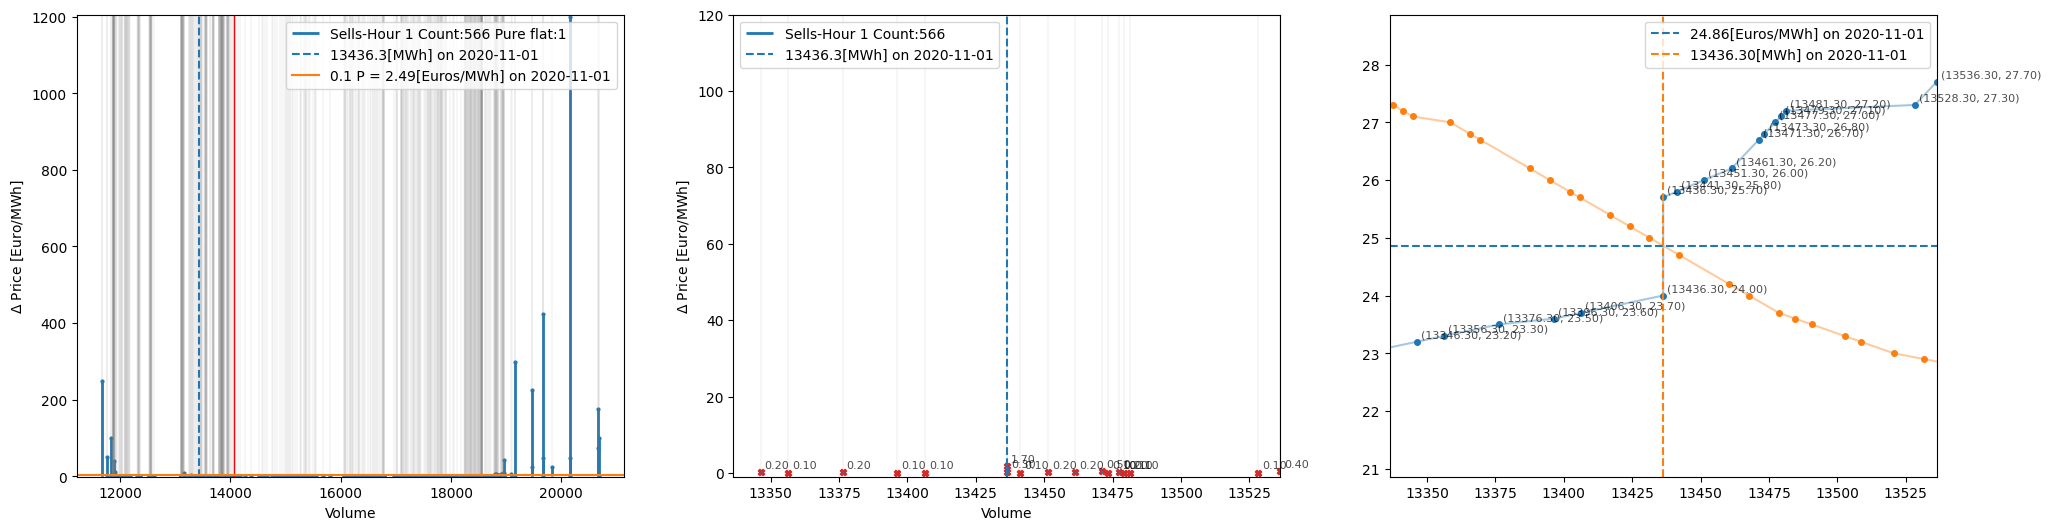

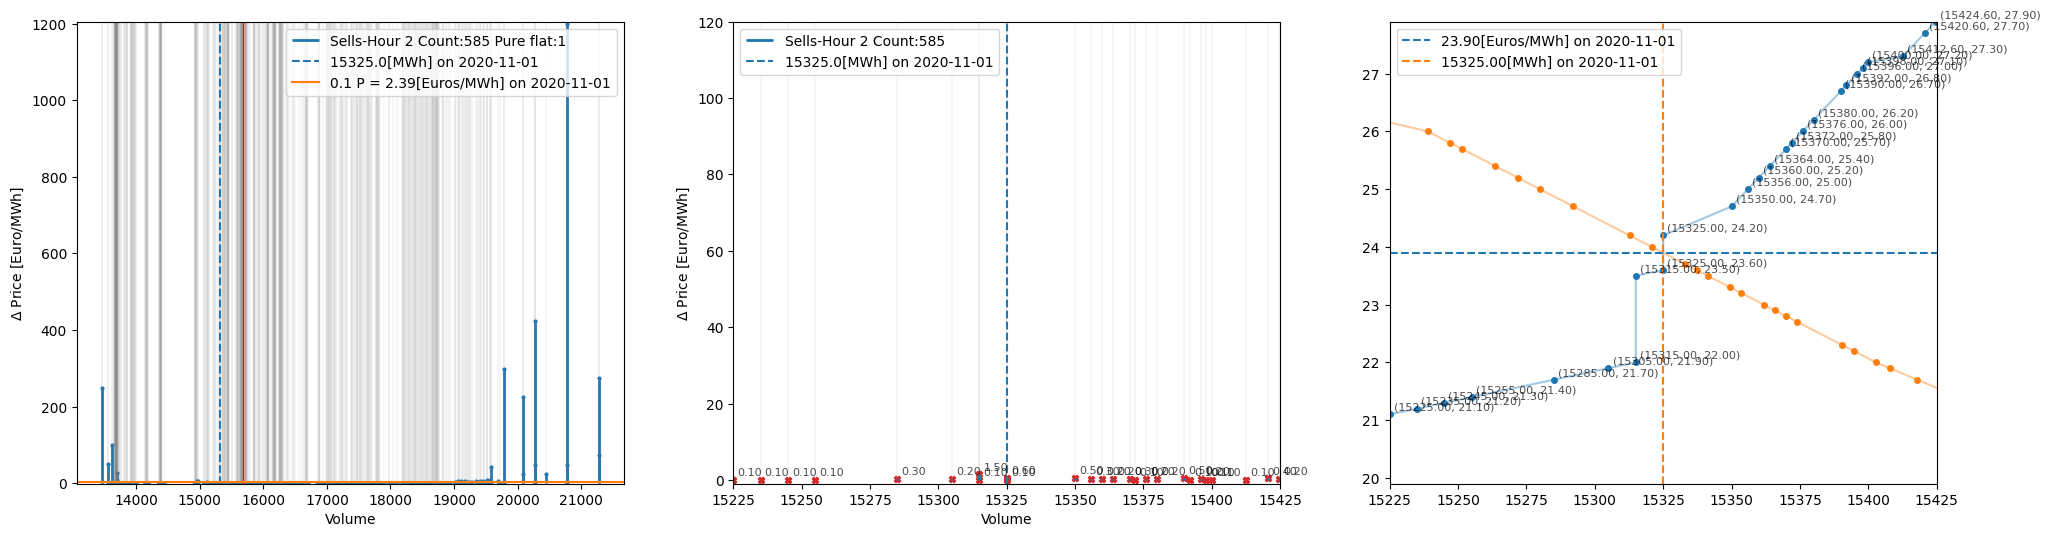

KeyboardInterrupt: 

In [ ]:
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells[full_test_file_sells['Hour'] == hour].copy()
  DPrice_max = Sells['DPrice'].max()
  Sells_0 = Sells[Sells['DPrice']==0]

  Purchases = full_test_file_purchases[full_test_file_purchases['Hour'] == hour].copy()

  Date_ = Sells['Date'].iloc[0]
  Price_ = Epex_Intersections[(Epex_Intersections['Date']==Date_)&(Epex_Intersections['Hour']==hour)]['Price'].values[0]
  Volume_ = Epex_Intersections[(Epex_Intersections['Date']==Date_)&(Epex_Intersections['Hour']==hour)]['Volume'].values[0]


  fig, ax = plt.subplots(1,3, figsize=(24, 6))

  ax[0].vlines(x=Sells['Volume'], ymin=0, ymax=Sells['DPrice'], linewidth=2, alpha=1, label=f'Sells-Hour {hour} Count:{Sells.shape[0]} Pure flat:{Sells_0.shape[0]}', color='C0')
  ax[1].vlines(x=Sells['Volume'], ymin=0, ymax=Sells['DPrice'], linewidth=2, alpha=1, label=f'Sells-Hour {hour} Count:{Sells.shape[0]}', color='C0')

  ax[0].scatter(Sells['Volume'], Sells['DPrice'], marker='o', color='C0', s=4)
  ax[1].scatter(Sells['Volume'], Sells['DPrice'], marker='X', color='C3', s=20)
  for x, y in zip(Sells['Volume'], Sells['DPrice']):
    ax[1].annotate(
        f"{y:.2f}",        # text to display
        (x, y),                     # point to label
        textcoords="offset points", # how to position text
        xytext=(3, 3),              # offset (x,y) in points
        fontsize=8,                 # smaller font
        alpha=0.7
    )

  ax[0].set_xlabel('Volume')
  ax[1].set_xlabel('Volume')
  ax[0].set_ylabel('$\Delta$ Price [Euro/MWh]')
  ax[1].set_ylabel('$\Delta$ Price [Euro/MWh]')

  for value in Sells['Volume']:
    ax[0].axvline(x=value, linestyle='-', linewidth=0.1, color = 'gray', alpha=1)
    ax[1].axvline(x=value, linestyle='-', linewidth=0.1, color = 'gray', alpha=1)
    ax[2].axhline(y=value, linestyle='-', linewidth=0.1, color = 'gray', alpha=1)

  for value in Sells_0['Volume']:
    ax[0].axvline(x=value, linestyle='-', linewidth=1, color = 'red', alpha=1)
    ax[1].axvline(x=value, linestyle='-', linewidth=1, color = 'red', alpha=1)
    ax[2].axhline(y=value, linestyle='-', linewidth=1, color = 'red', alpha=1)

  ax[2].scatter(Sells['Volume'].values, Sells['Price'].values, s=16)
  ax[2].plot(Sells['Volume'].values, Sells['Price'].values, alpha=0.4)
  for x, y in zip(Sells['Volume'], Sells['Price']):
    ax[2].annotate(
        f"({x:.2f}, {y:.2f})",        # text to display
        (x, y),                     # point to label
        textcoords="offset points", # how to position text
        xytext=(3, 3),              # offset (x,y) in points
        fontsize=8,                 # smaller font
        alpha=0.7
    )
  ax[2].scatter(Purchases['Volume'].values, Purchases['Price'].values, s=16)
  ax[2].plot(Purchases['Volume'].values, Purchases['Price'].values, alpha=0.4)

  ax[0].axvline(x=Volume_, linestyle='--', label=f"{Volume_:.1f}[MWh] on {str(peaks_dates[idx_test].date())}")
  ax[0].axhline(y=Price_/10, linestyle='-', color='tab:orange', label=f"0.1 P = {Price_/10:.2f}[Euros/MWh] on {str(peaks_dates[idx_test].date())}")
  ax[1].axvline(x=Volume_, linestyle='--', label=f"{Volume_:.1f}[MWh] on {str(peaks_dates[idx_test].date())}")
  ax[2].axhline(y=Price_, linestyle='--', label=f"{Price_:.2f}[Euros/MWh] on {str(peaks_dates[idx_test].date())}")
  ax[2].axvline(x=Volume_, linestyle='--', color='tab:orange', label=f"{Volume_:.2f}[MWh] on {str(peaks_dates[idx_test].date())}")

  ax[0].legend()
  ax[1].legend()
  ax[2].legend()

  ax[0].set_ylim([-1,DPrice_max+5])
  ax[1].set_ylim([-1,DPrice_max/10])
  ax[2].set_ylim([Price_-4,Price_+4])
  ax[1].set_xlim([Volume_-100, Volume_+100])
  ax[2].set_xlim([Volume_-100,Volume_+100])

  plt.show()

In [ ]:
bins = np.array([0, 1, 10, 100, 2000])
bins_colors=['purple', 'blue', 'green', 'tab:orange']
print(bins)

[   0    1   10  100 2000]


In [ ]:
DPrice_dict={}
for bin in range(len(bins)-1):
  DPrice_dict[bin]=full_test_file_sells[full_test_file_sells['DPrice'].between(bins[bin], bins[bin+1], inclusive='right')].copy()
  print(bins[bin], bins[bin+1])


for bin in range(len(bins)-1):
  print(f"{bin}: {DPrice_dict[bin].shape[0]}, Volume range: {DPrice_dict[bin]['Volume'].min()} to {DPrice_dict[bin]['Volume'].max()}")

print(f"{full_test_file_sells['Volume'].min()} to {full_test_file_sells['Volume'].max()}")

0 1
1 10
10 100
100 2000
0: 11486, Volume range: 11766.8 to 30973.9
1: 783, Volume range: 11871.1 to 29458.9
2: 237, Volume range: 11766.8 to 30973.9
3: 143, Volume range: 11665.8 to 30958.9
11665.8 to 30973.9


In [ ]:
aggregate_DPrice_byVol=[]
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells[full_test_file_sells['Hour'] == hour].copy()
  min_ = Sells['Volume'].values.min()
  max_ = Sells['Volume'].values.max()
  temp_ = aggregate_by_grid(np.arange(min_, max_, 1000),
                            Sells['Volume'].values[1:], Sells['DPrice'][1:].values)
  temp_['Hour']=hour
  temp_['Date']=Sells['Date'].iloc[0]
  aggregate_DPrice_byVol.append(temp_)
aggregate_DPrice_byVol_main = pd.concat(aggregate_DPrice_byVol)


aggregate_DPrice_byVol = aggregate_DPrice_byVol_main.pivot(index='Hour', columns='x', values='y_sum')
aggregate_DPrice_byVol['Date']=Sells['Date'].iloc[0]
aggregate_DPrice_byVol.reset_index(inplace=True)

#aggregate_DPrice_byVol = aggregate_DPrice_byVol.fillna(0)

Date_ = Sells['Date'].iloc[0]
Price_ = Epex_Intersections[(Epex_Intersections['Date']==Date_)][['Price','Hour']].values
Volume_ = Epex_Intersections[(Epex_Intersections['Date']==Date_)][['Volume','Hour']].values

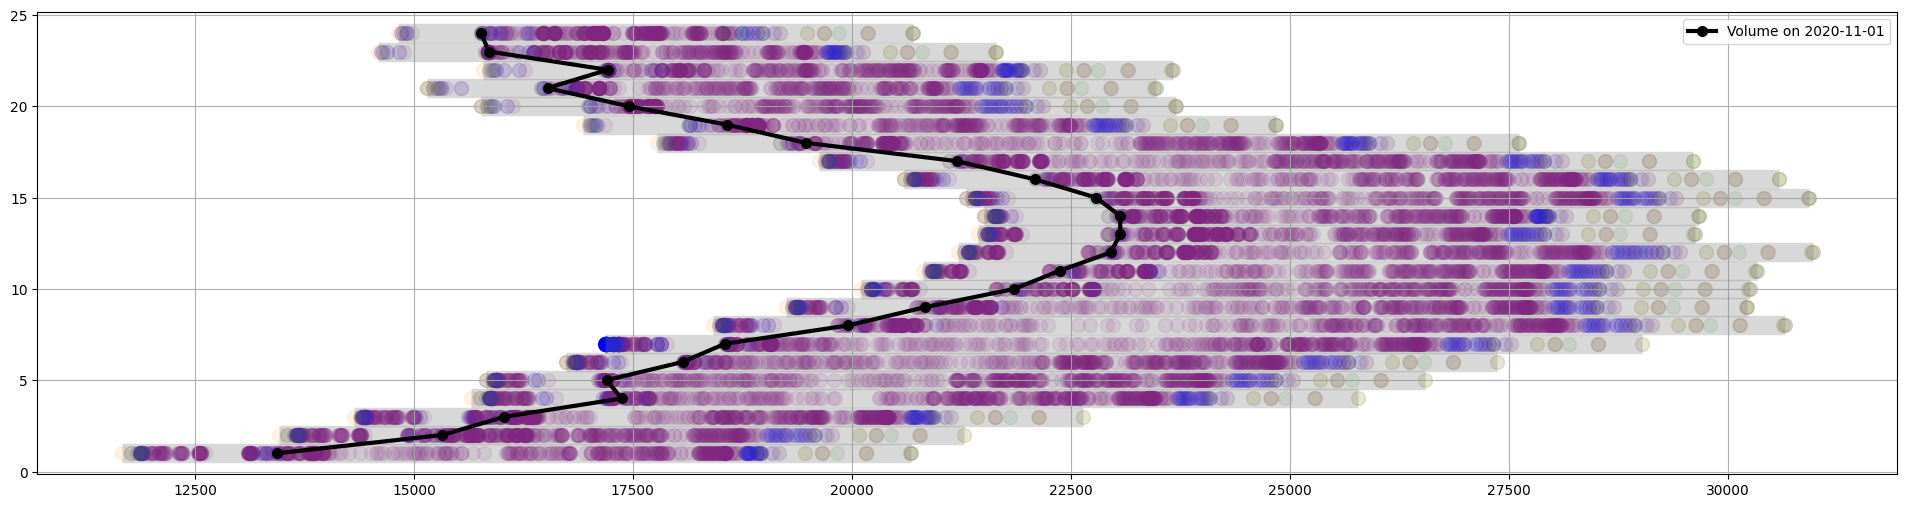

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells[full_test_file_sells['Hour'] == hour].copy()
  min_ = Sells['Volume'].values.min()
  max_ = Sells['Volume'].values.max()
  ax.hlines(y=hour, xmin=min_, xmax=max_, linestyle='-', color='gray', linewidth=14, alpha=0.3)

  for bin in range(len(bins)-1):
    values_temp = DPrice_dict[bin][DPrice_dict[bin]['Hour']==hour]
    ax.scatter(values_temp['Volume'].values, hour*np.ones_like(values_temp['Volume'].values), color=bins_colors[bin], s=100, alpha=0.1)


ax.plot(Volume_[:,0], Volume_[:,1], color='black', linestyle='-', marker='o', markersize=7, linewidth=3, label=f'Volume on {str(Date_.date())}')
plt.legend()
#ax.set_facecolor('lightgray')
plt.show()

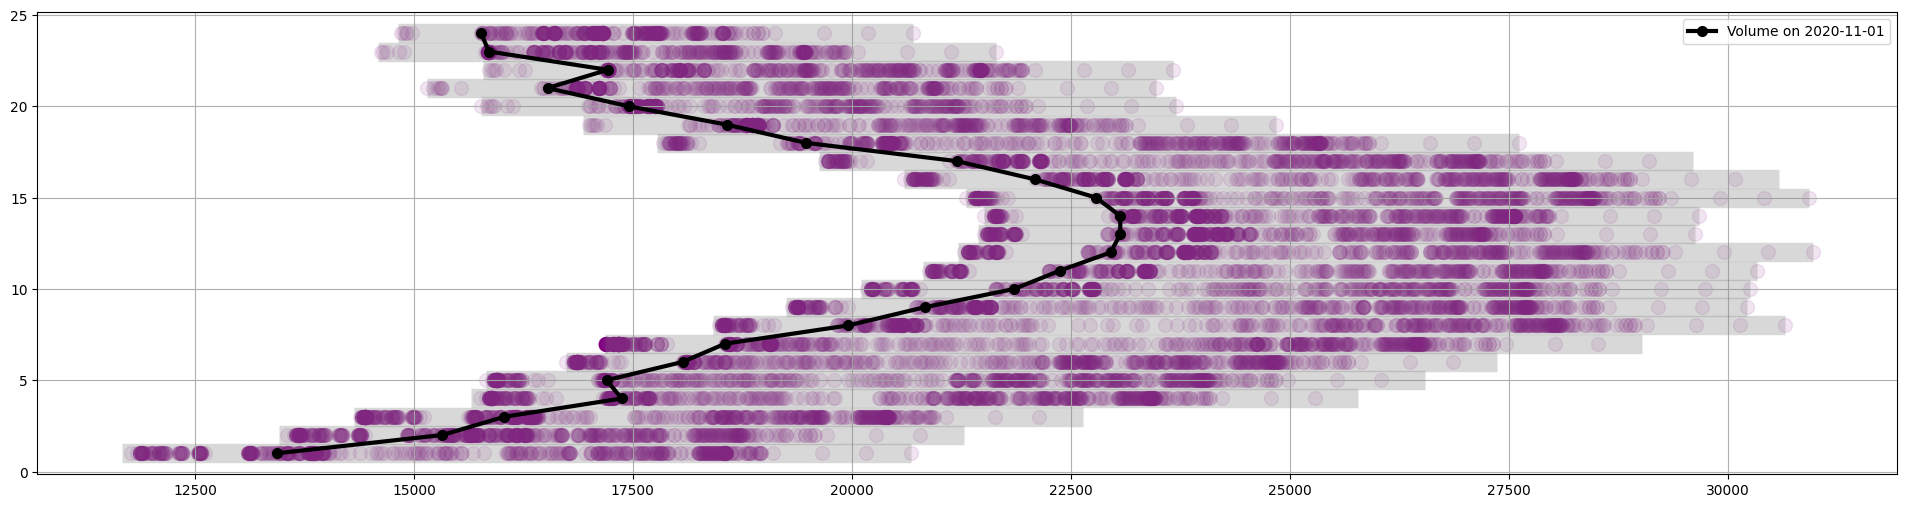

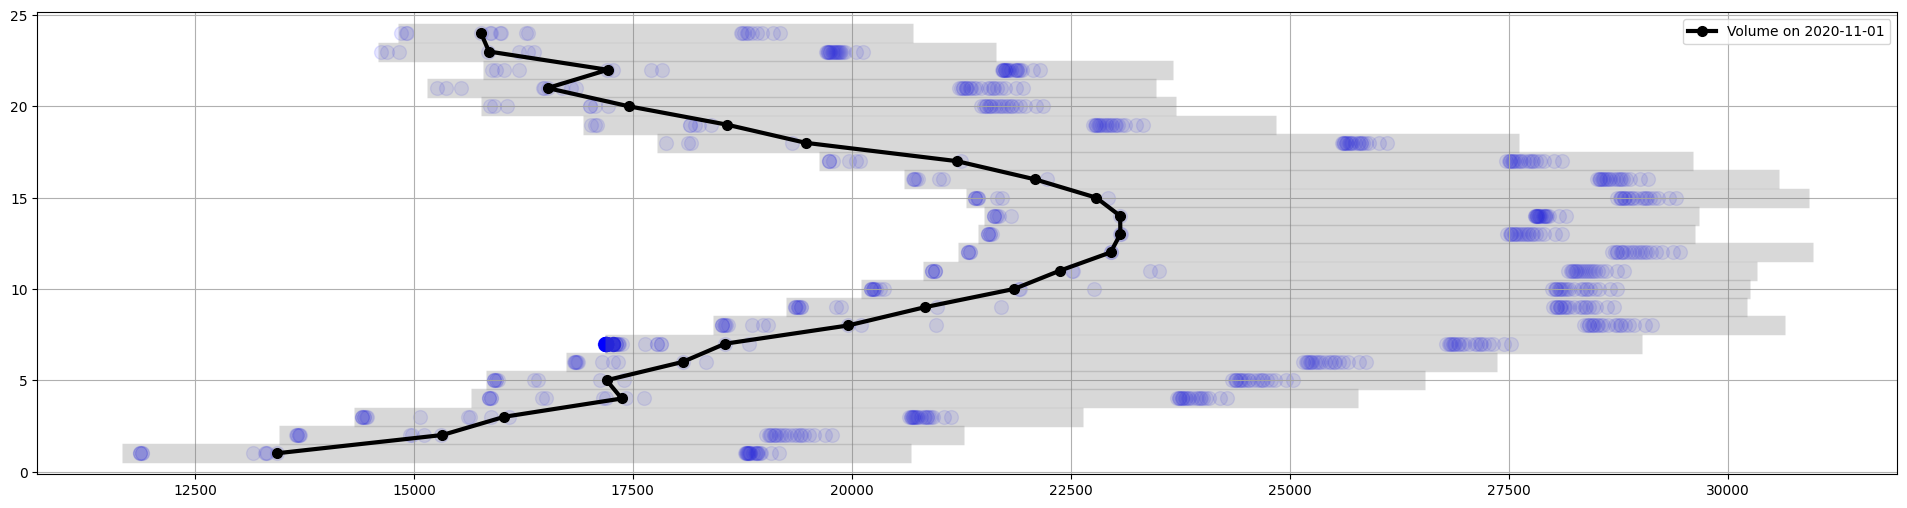

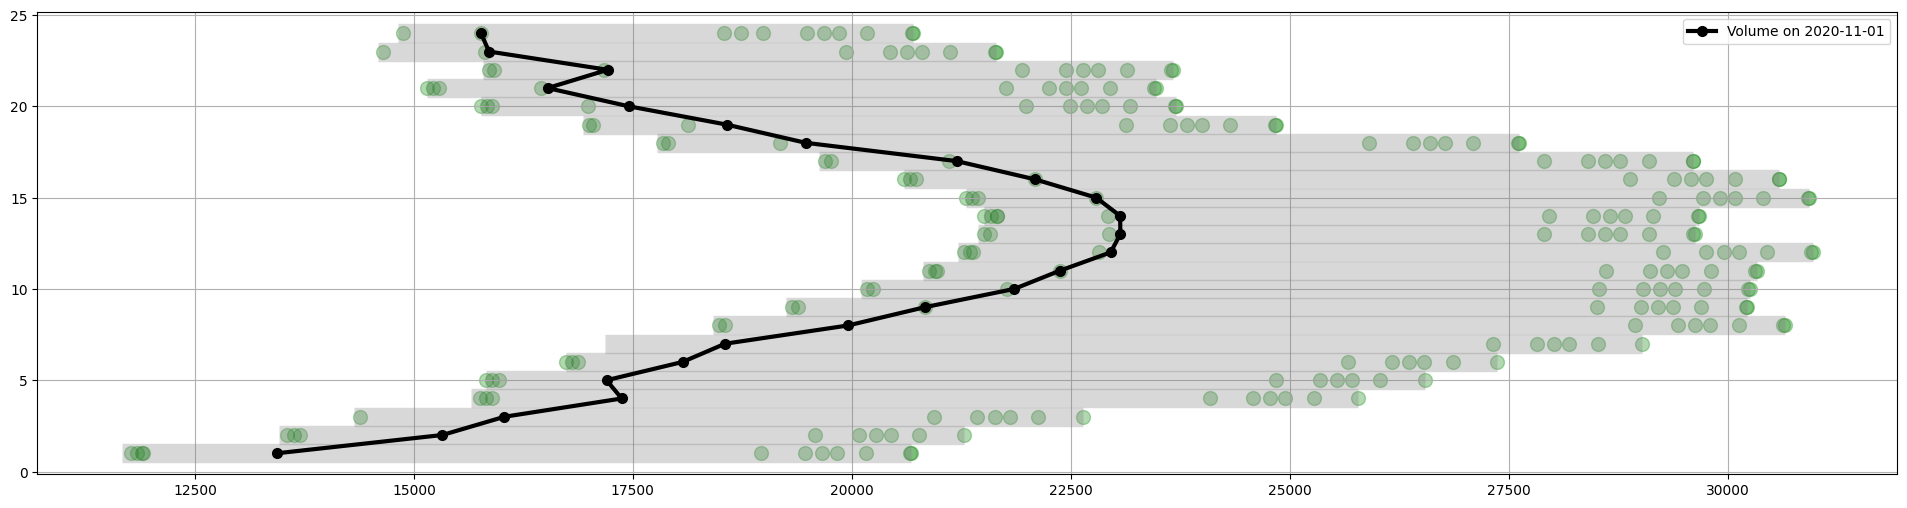

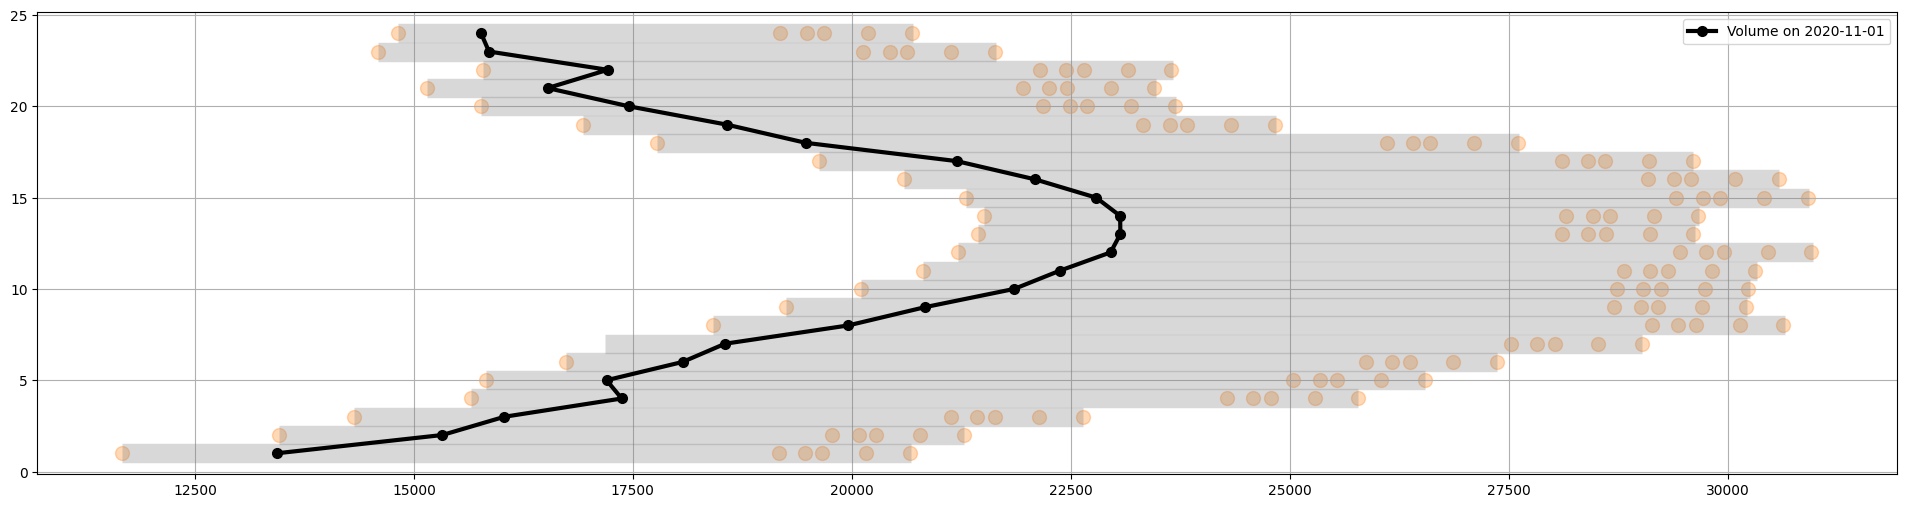

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells[full_test_file_sells['Hour'] == hour].copy()
  min_ = Sells['Volume'].values.min()
  max_ = Sells['Volume'].values.max()
  ax.hlines(y=hour, xmin=min_, xmax=max_, linestyle='-', color='gray', linewidth=14, alpha=0.3)

  values_temp = DPrice_dict[0][DPrice_dict[0]['Hour']==hour]
  ax.scatter(values_temp['Volume'].values, hour*np.ones_like(values_temp['Volume'].values), color=bins_colors[0], s=100, alpha=0.1)


ax.plot(Volume_[:,0], Volume_[:,1], color='black', linestyle='-', marker='o', markersize=7, linewidth=3, label=f'Volume on {str(Date_.date())}')
plt.legend()
#ax.set_facecolor('lightgray')
plt.show()



fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells[full_test_file_sells['Hour'] == hour].copy()
  min_ = Sells['Volume'].values.min()
  max_ = Sells['Volume'].values.max()
  ax.hlines(y=hour, xmin=min_, xmax=max_, linestyle='-', color='gray', linewidth=14, alpha=0.3)

  values_temp = DPrice_dict[1][DPrice_dict[1]['Hour']==hour]
  ax.scatter(values_temp['Volume'].values, hour*np.ones_like(values_temp['Volume'].values), color=bins_colors[1], s=100, alpha=0.1)


ax.plot(Volume_[:,0], Volume_[:,1], color='black', linestyle='-', marker='o', markersize=7, linewidth=3, label=f'Volume on {str(Date_.date())}')
plt.legend()
#ax.set_facecolor('lightgray')
plt.show()


fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells[full_test_file_sells['Hour'] == hour].copy()
  min_ = Sells['Volume'].values.min()
  max_ = Sells['Volume'].values.max()
  ax.hlines(y=hour, xmin=min_, xmax=max_, linestyle='-', color='gray', linewidth=14, alpha=0.3)

  values_temp = DPrice_dict[2][DPrice_dict[2]['Hour']==hour]
  ax.scatter(values_temp['Volume'].values, hour*np.ones_like(values_temp['Volume'].values), color=bins_colors[2], s=100, alpha=0.3)


ax.plot(Volume_[:,0], Volume_[:,1], color='black', linestyle='-', marker='o', markersize=7, linewidth=3, label=f'Volume on {str(Date_.date())}')
plt.legend()
#ax.set_facecolor('lightgray')
plt.show()


fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells[full_test_file_sells['Hour'] == hour].copy()
  min_ = Sells['Volume'].values.min()
  max_ = Sells['Volume'].values.max()
  ax.hlines(y=hour, xmin=min_, xmax=max_, linestyle='-', color='gray', linewidth=14, alpha=0.3)

  values_temp = DPrice_dict[3][DPrice_dict[3]['Hour']==hour]
  ax.scatter(values_temp['Volume'].values, hour*np.ones_like(values_temp['Volume'].values), color=bins_colors[3], s=100, alpha=0.3)


ax.plot(Volume_[:,0], Volume_[:,1], color='black', linestyle='-', marker='o', markersize=7, linewidth=3, label=f'Volume on {str(Date_.date())}')
plt.legend()
#ax.set_facecolor('lightgray')
plt.show()

#Normalized Volume

In [ ]:
normalizer = MinMaxNormalizer()
full_test_file_sells_QN = normalizer.fit_transform(full_test_file_sells, value_col="Volume", hour_col="Hour")

In [ ]:
full_test_file_sells_QN

,Date,Week,Week Day,Hour,Price,Volume,Sale/Purchase,DVolume,DPrice
0,2020-11-01,44,7,1,-500.0,0.000000,Sell,11665.8,-500.0
1,2020-11-01,44,7,1,-250.1,0.000000,Sell,0.0,249.9
2,2020-11-01,44,7,1,-250.0,0.011205,Sell,101.0,0.1
3,2020-11-01,44,7,1,-200.1,0.011205,Sell,0.0,49.9
4,2020-11-01,44,7,1,-200.0,0.018970,Sell,70.0,0.1
...,...,...,...,...,...,...,...,...,...
24080,2020-11-01,44,7,24,2650.0,0.912457,Sell,0.0,1200.0
24081,2020-11-01,44,7,24,2725.0,0.997450,Sell,500.0,75.0
24082,2020-11-01,44,7,24,2900.0,0.997450,Sell,0.0,175.0
24083,2020-11-01,44,7,24,2900.1,1.000000,Sell,15.0,0.1


In [ ]:
DPriceQN_dict={}
for bin in range(len(bins)-1):
  DPriceQN_dict[bin]=full_test_file_sells_QN[full_test_file_sells_QN['DPrice'].between(bins[bin], bins[bin+1], inclusive='right')].copy()
  print(bins[bin], bins[bin+1])


for bin in range(len(bins)-1):
  print(f"{bin}: {DPriceQN_dict[bin].shape[0]}, Volume range: {DPriceQN_dict[bin]['Volume'].min()} to {DPriceQN_dict[bin]['Volume'].max()}")

print(f"{full_test_file_sells_QN['Volume'].min()} to {full_test_file_sells_QN['Volume'].max()}")

0 1
1 10
10 100
100 2000
0: 11486, Volume range: 9.328619271061692e-05 to 1.0
1: 783, Volume range: 8.445517963493812e-06 to 0.8761779441452191
2: 237, Volume range: 9.328619271061692e-05 to 1.0
3: 143, Volume range: 0.0 to 1.0
0.0 to 1.0


In [ ]:
aggregate_DPrice_byVolQN=[]
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells_QN[full_test_file_sells_QN['Hour'] == hour].copy()
  min_ = Sells['Volume'].values.min()
  max_ = Sells['Volume'].values.max()
  temp_ = aggregate_by_grid(np.arange(min_, max_, 0.1),
                            Sells['Volume'].values[1:], Sells['DPrice'][1:].values)
  temp_['Hour']=hour
  temp_['Date']=Sells['Date'].iloc[0]
  aggregate_DPrice_byVolQN.append(temp_)
aggregate_DPrice_byVolQN_main = pd.concat(aggregate_DPrice_byVolQN)


aggregate_DPrice_byVolQN = aggregate_DPrice_byVolQN_main.pivot(index='Hour', columns='x', values='y_sum')
aggregate_DPrice_byVolQN['Date']=Sells['Date'].iloc[0]
aggregate_DPrice_byVolQN.reset_index(inplace=True)

#aggregate_DPrice_byVolQN = aggregate_DPrice_byVolQN.fillna(0)

Date_ = Sells['Date'].iloc[0]
Price_ = Epex_Intersections[(Epex_Intersections['Date']==Date_)][['Price','Hour']].values
Volume_ = normalizer.transform(Epex_Intersections[(Epex_Intersections['Date']==Date_)][['Volume','Hour']], value_col="Volume", hour_col="Hour").values


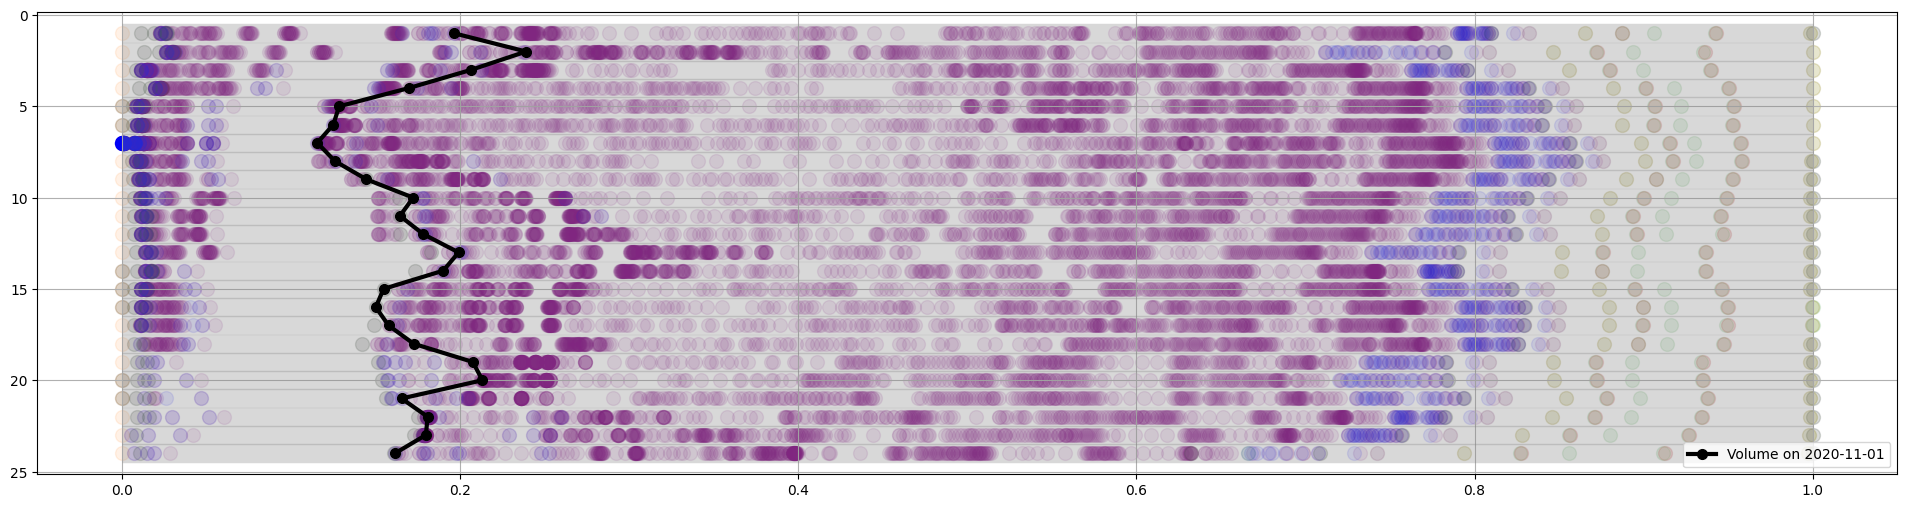

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells_QN[full_test_file_sells_QN['Hour'] == hour].copy()
  min_ = Sells['Volume'].values.min()
  max_ = Sells['Volume'].values.max()
  ax.hlines(y=hour, xmin=min_, xmax=max_, linestyle='-', color='gray', linewidth=14, alpha=0.3)

  for bin in range(len(bins)-1):
    values_temp = DPriceQN_dict[bin][DPriceQN_dict[bin]['Hour']==hour]
    ax.scatter(values_temp['Volume'].values, hour*np.ones_like(values_temp['Volume'].values), color=bins_colors[bin], s=100, alpha=0.1)


ax.plot(Volume_[:,0], Volume_[:,1], color='black', linestyle='-', marker='o', markersize=7, linewidth=3, label=f'Volume on {str(Date_.date())}')
plt.legend()
ax.yaxis.set_inverted(True)
#ax.set_facecolor('lightgray')
plt.show()

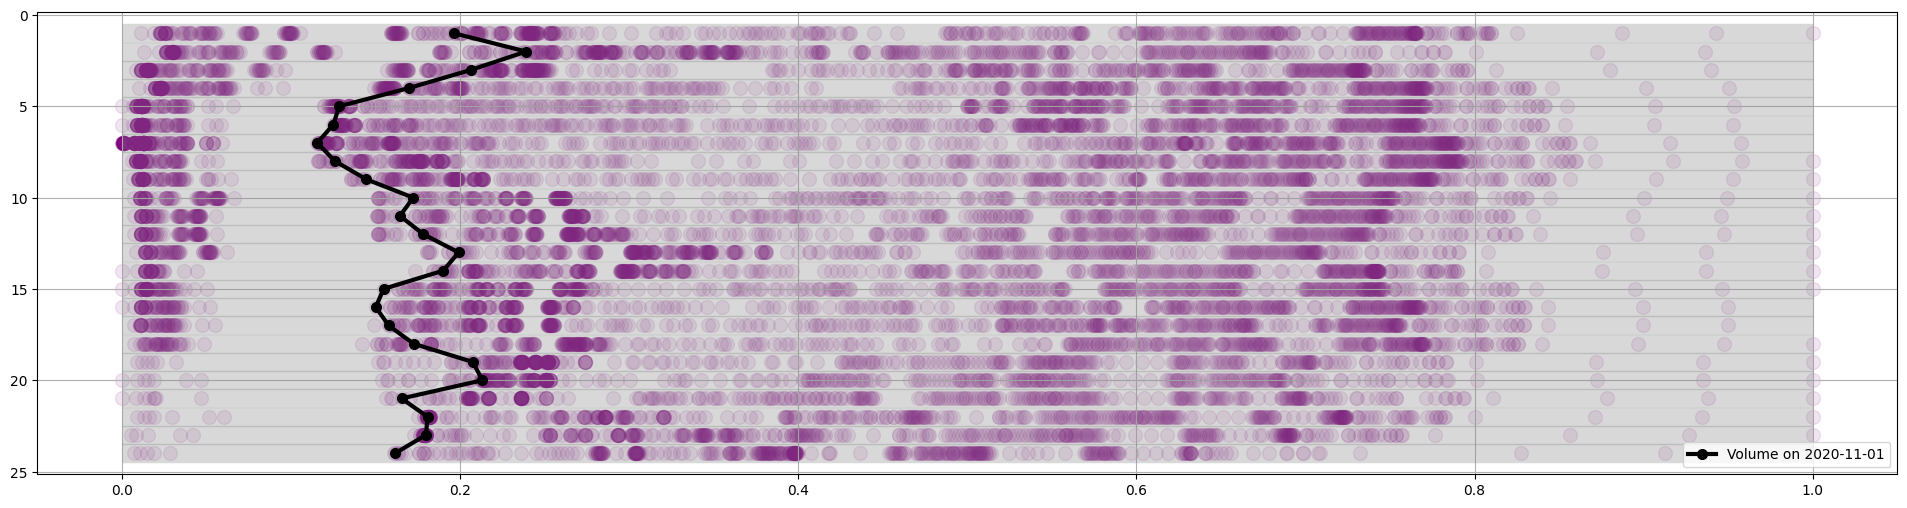

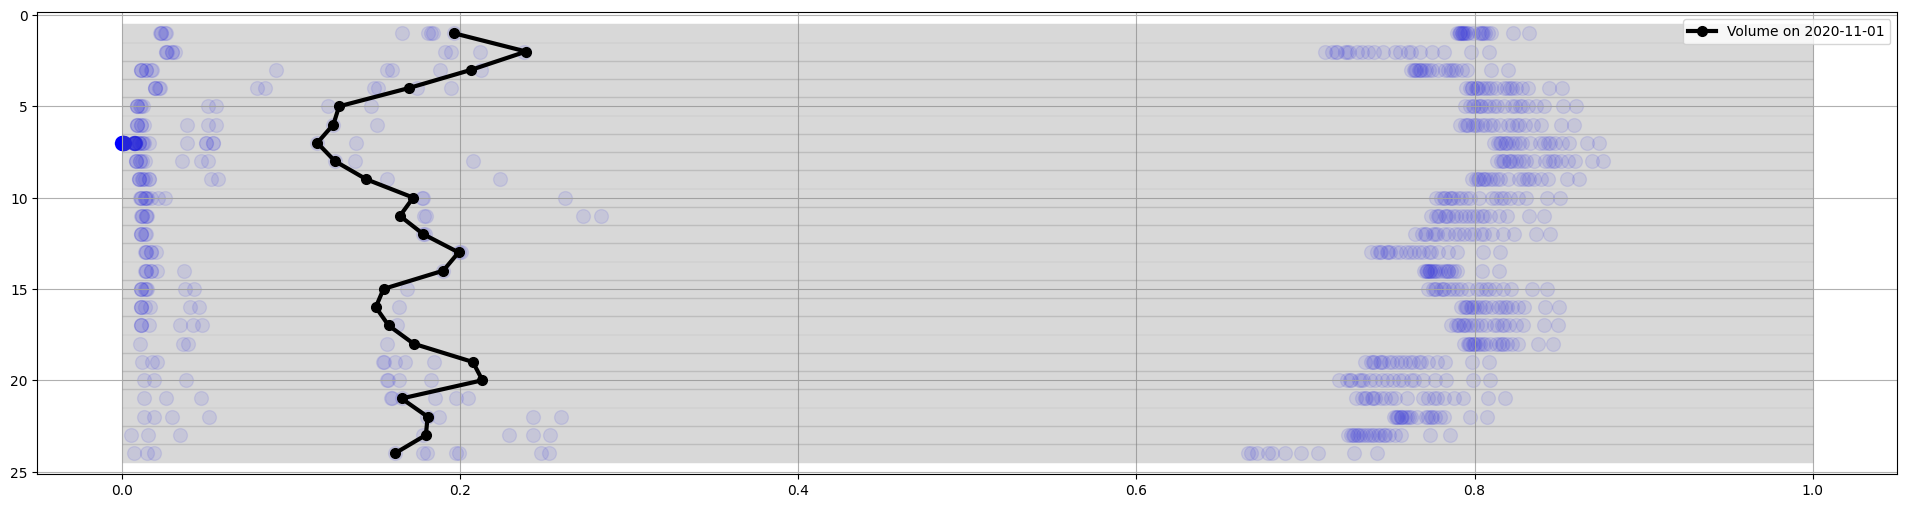

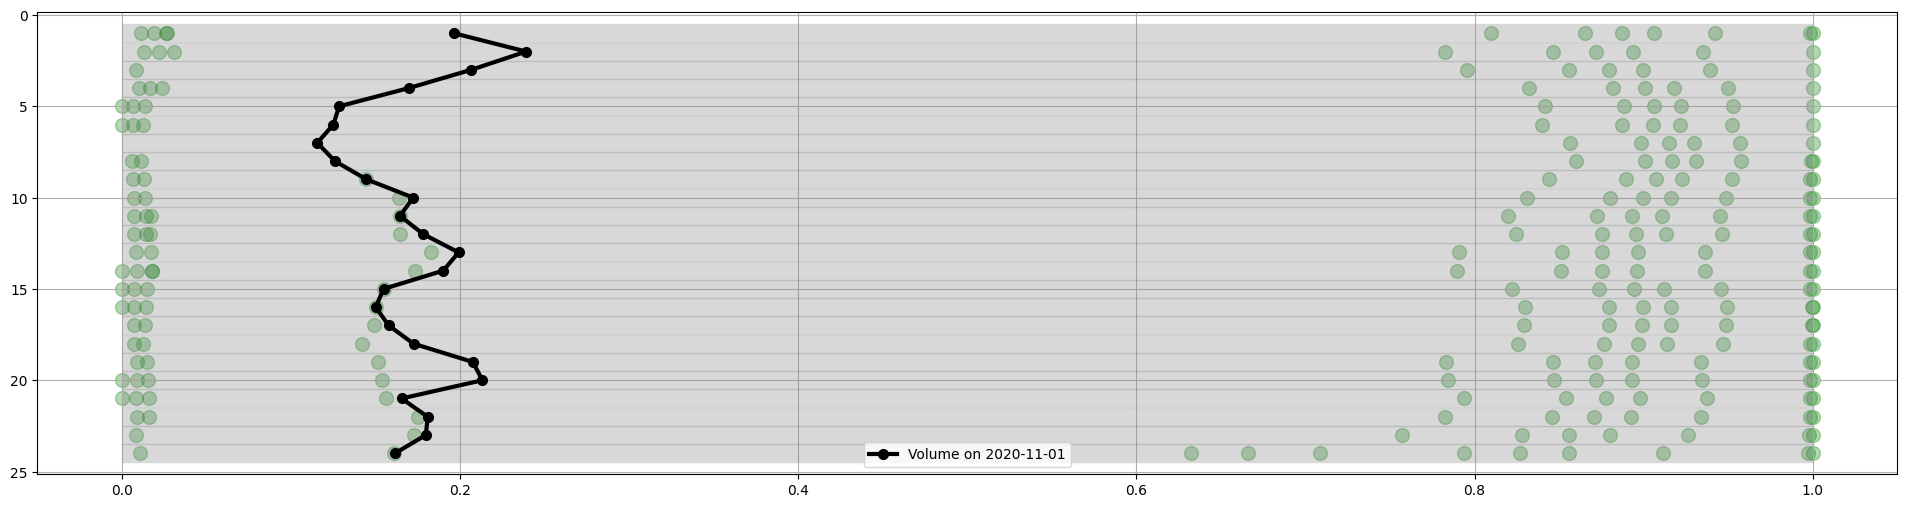

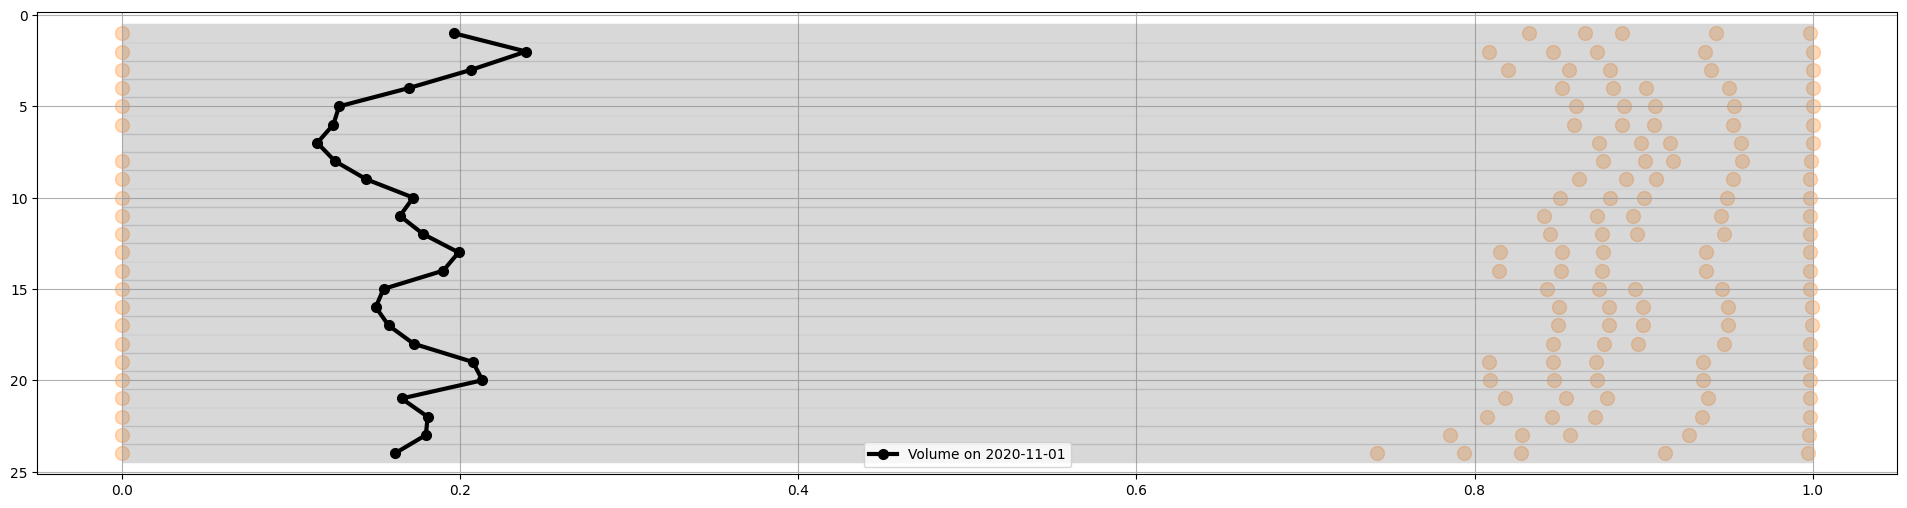

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells_QN[full_test_file_sells_QN['Hour'] == hour].copy()
  min_ = Sells['Volume'].values.min()
  max_ = Sells['Volume'].values.max()
  ax.hlines(y=hour, xmin=min_, xmax=max_, linestyle='-', color='gray', linewidth=14, alpha=0.3)

  values_temp = DPriceQN_dict[0][DPriceQN_dict[0]['Hour']==hour]
  ax.scatter(values_temp['Volume'].values, hour*np.ones_like(values_temp['Volume'].values), color=bins_colors[0], s=100, alpha=0.1)


ax.plot(Volume_[:,0], Volume_[:,1], color='black', linestyle='-', marker='o', markersize=7, linewidth=3, label=f'Volume on {str(Date_.date())}')
plt.legend()
ax.yaxis.set_inverted(True)
#ax.set_facecolor('lightgray')
plt.show()



fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells_QN[full_test_file_sells_QN['Hour'] == hour].copy()
  min_ = Sells['Volume'].values.min()
  max_ = Sells['Volume'].values.max()
  ax.hlines(y=hour, xmin=min_, xmax=max_, linestyle='-', color='gray', linewidth=14, alpha=0.3)

  values_temp = DPriceQN_dict[1][DPriceQN_dict[1]['Hour']==hour]
  ax.scatter(values_temp['Volume'].values, hour*np.ones_like(values_temp['Volume'].values), color=bins_colors[1], s=100, alpha=0.1)


ax.plot(Volume_[:,0], Volume_[:,1], color='black', linestyle='-', marker='o', markersize=7, linewidth=3, label=f'Volume on {str(Date_.date())}')
plt.legend()
ax.yaxis.set_inverted(True)
#ax.set_facecolor('lightgray')
plt.show()



fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells_QN[full_test_file_sells_QN['Hour'] == hour].copy()
  min_ = Sells['Volume'].values.min()
  max_ = Sells['Volume'].values.max()
  ax.hlines(y=hour, xmin=min_, xmax=max_, linestyle='-', color='gray', linewidth=14, alpha=0.3)

  values_temp = DPriceQN_dict[2][DPriceQN_dict[2]['Hour']==hour]
  ax.scatter(values_temp['Volume'].values, hour*np.ones_like(values_temp['Volume'].values), color=bins_colors[2], s=100, alpha=0.3)


ax.plot(Volume_[:,0], Volume_[:,1], color='black', linestyle='-', marker='o', markersize=7, linewidth=3, label=f'Volume on {str(Date_.date())}')
plt.legend()
ax.yaxis.set_inverted(True)
#ax.set_facecolor('lightgray')
plt.show()


fig, ax = plt.subplots(1,1, figsize=(24, 6))
plt.grid()
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells_QN[full_test_file_sells_QN['Hour'] == hour].copy()
  min_ = Sells['Volume'].values.min()
  max_ = Sells['Volume'].values.max()
  ax.hlines(y=hour, xmin=min_, xmax=max_, linestyle='-', color='gray', linewidth=14, alpha=0.3)

  values_temp = DPriceQN_dict[3][DPriceQN_dict[3]['Hour']==hour]
  ax.scatter(values_temp['Volume'].values, hour*np.ones_like(values_temp['Volume'].values), color=bins_colors[3], s=100, alpha=0.3)


ax.plot(Volume_[:,0], Volume_[:,1], color='black', linestyle='-', marker='o', markersize=7, linewidth=3, label=f'Volume on {str(Date_.date())}')
plt.legend()
ax.yaxis.set_inverted(True)
#ax.set_facecolor('lightgray')
plt.show()

#Model for the $$\Delta P \in (0,1]$$

In [ ]:
t_arrDP0 = DPriceQN_dict[0]['Volume'].unique()

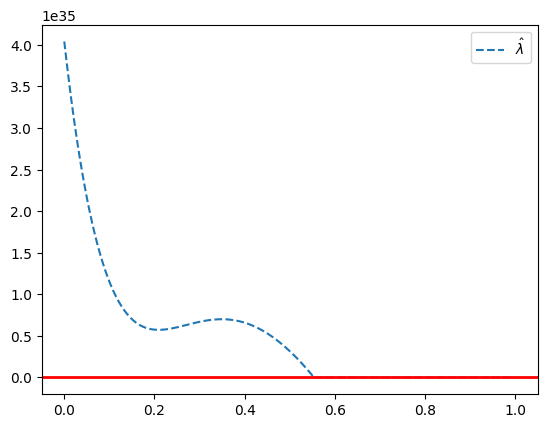

KeyboardInterrupt: 

In [ ]:
NonHPP_polyL=GlobalPolyNHPP()
NonHPP_polyL.fit(t_arrDP0)
NonHPP_polyL.flag

grid = np.linspace(0,1,1000)
lam = NonHPP_polyL.predict(grid)

plt.plot(grid, lam, '--', label='$\hat{\lambda}$')
plt.axhline(0, color='r', lw=2)
plt.legend()
plt.show()

sim_times = NonHPP_polyL.simulate(random_state=12)
NonHPP_polyL.goodness_of_fit(sim_times)

#DPrice vs DVolume

In [ ]:
aggregate_DPrice_byDVol=[]
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells[full_test_file_sells['Hour'] == hour].copy()
  Sells.sort_values(by=['DVolume'], inplace=True)

  temp_ = aggregate_by_grid(bins,
                  Sells['DVolume'].values[:-1], Sells['DPrice'][:-1].values)
  temp_['Hour']=hour
  temp_['Date']=Sells['Date'].iloc[0]
  aggregate_DPrice_byDVol.append(temp_)
aggregate_DPrice_byDVol_main = pd.concat(aggregate_DPrice_byDVol)


In [ ]:
aggregate_DPrice_byDVol = aggregate_DPrice_byDVol_main.pivot(index='Hour', columns='x', values='y_sum')
aggregate_DPrice_byDVol['Date']=Sells['Date'].iloc[0]
aggregate_DPrice_byDVol.reset_index(inplace=True)

In [ ]:
for hour in [i+1 for i in range(24)]:#[19,20]:#[i+1 for i in range(24)]:
  print(hour, aggregate_DPrice_byDVol.iloc[hour-1][1:-1].sum())

1 3499.9999999999995
2 3500.0000000000005
3 3500.0
4 3499.9
5 3499.9999999999995
6 3500.0000000000005
7 3500.0
8 3500.0
9 3500.0
10 3500.0
11 3500.0
12 3500.0
13 3499.9999999999995
14 3500.0
15 3500.0000000000005
16 3500.0
17 3499.9999999999995
18 3499.9999999999995
19 3499.999999999999
20 3500.0
21 3500.0
22 3500.0
23 3499.8999999999996
24 3500.0


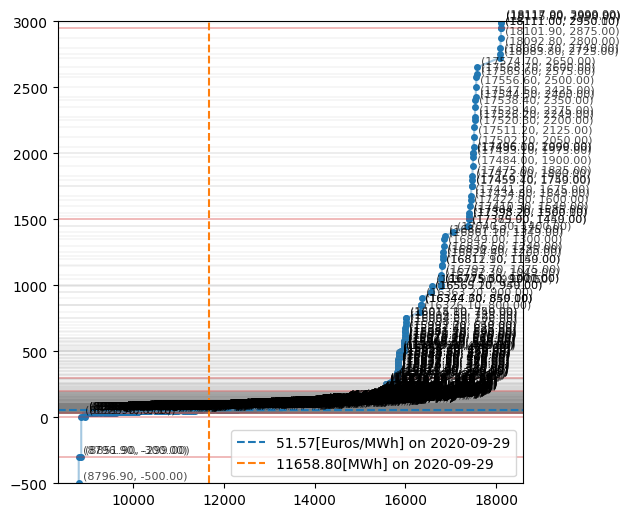

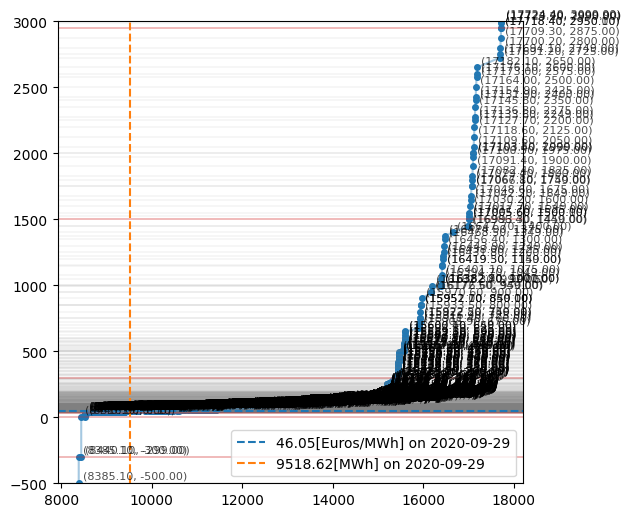

In [ ]:
for hour in [23,24]:#[19,20]:#[i+1 for i in range(24)]:
  Sells = full_test_file_sells[full_test_file_sells['Hour'] == hour].copy()
  Sells_0 = Sells[Sells['DVolume']==0]

  Purchases = full_test_file_purchases[full_test_file_purchases['Hour'] == hour].copy()

  Date_ = Sells['Date'].iloc[0]
  Price_ = Epex_Intersections[(Epex_Intersections['Date']==Date_)&(Epex_Intersections['Hour']==hour)]['Price'].values[0]
  Volume_t = Epex_Intersections[(Epex_Intersections['Date']==Date_)&(Epex_Intersections['Hour']==hour)]['Volume'].values[0]


  fig = plt.subplots(figsize=(6, 6))

  for value in Sells['Price']:
    plt.axhline(y=value, linestyle='-', linewidth=0.1, color = 'gray', alpha=1)

  for value in Sells_0['Price']:
    plt.axhline(y=value, linestyle='-', linewidth=0.3, color = 'red', alpha=1)

  plt.scatter(Sells['Volume'].values, Sells['Price'].values, s=16)
  plt.plot(Sells['Volume'].values, Sells['Price'].values, alpha=0.4)
  for x, y in zip(Sells['Volume'], Sells['Price']):
    plt.annotate(
        f"({x:.2f}, {y:.2f})",        # text to display
        (x, y),                     # point to label
        textcoords="offset points", # how to position text
        xytext=(3, 3),              # offset (x,y) in points
        fontsize=8,                 # smaller font
        alpha=0.7
    )
#  plt.scatter(Purchases['Volume'].values, Purchases['Price'].values, s=16)
#  plt.plot(Purchases['Volume'].values, Purchases['Price'].values, alpha=0.4)

  plt.axhline(y=Price_, linestyle='--', label=f"{Price_:.2f}[Euros/MWh] on {str(peaks_dates[idx_test].date())}")
  plt.axvline(x=Volume_t, linestyle='--', color='tab:orange', label=f"{Volume_t:.2f}[MWh] on {str(peaks_dates[idx_test].date())}")

  plt.legend()

  plt.ylim([-500,3000])   #  plt.set_xlim([-510,10])

  plt.show()


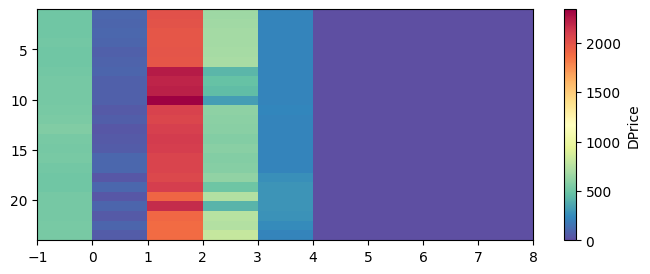

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(8, 3))
im = ax.imshow(aggregate_DPrice_byDVol.values[:,1:-1].astype(float), aspect='auto', origin='upper',
           cmap='Spectral_r', extent=[bins_keys[0], bins_keys[-1]+1, 24, 1] #on y it is lower, upper
           )
fig.colorbar(im, ax=ax, label='DPrice', orientation='vertical')
#ax.plot(Price_[:,0], Price_[:,1], color='black', linestyle='--', marker='o', markersize=4, linewidth=1)
plt.show()

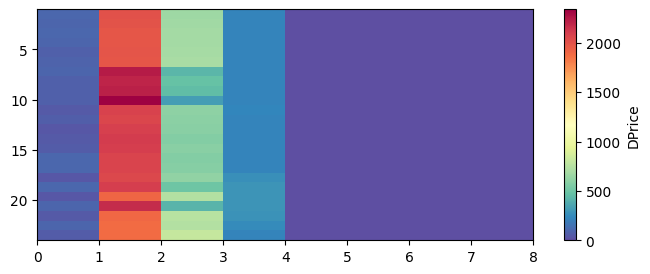

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(8, 3))
im = ax.imshow(aggregate_DPrice_byDVol.values[:,2:-1].astype(float), aspect='auto', origin='upper',
           cmap='Spectral_r', extent=[bins_keys[1], bins_keys[-1]+1, 24, 1] #on y it is lower, upper
           )
fig.colorbar(im, ax=ax, label='DPrice', orientation='vertical')
plt.show()

In [ ]:
! pip install hawkesbook

In [ ]:
import hawkesbook as hawkes

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from statsmodels.graphics.gofplots import qqplot



In [ ]:
# Calculate the maximum likelihood estimate for the Hawkes process
# with an exponentially decaying intensity
𝛉_exp_mle = hawkes.exp_mle(t_arrDV0, 1.0)
print("Exp Hawkes MLE fit: ", 𝛉_exp_mle)

# Calculate the EM estimate or the same type of Hawkes process
𝛉_exp_em = hawkes.exp_em(t_arrDV0, 1.0, iters=100)
print("Exp Hawkes EM fit: ", 𝛉_exp_mle)

# Get the likelihoods of each fit to find the better one
ll_mle = hawkes.exp_log_likelihood(t_arrDV0, 1.0, 𝛉_exp_mle)
ll_em = hawkes.exp_log_likelihood(t_arrDV0, 1.0, 𝛉_exp_em)

if ll_mle > ll_em:
	print("MLE was a better fit than EM in this case")
	𝛉_exp = 𝛉_exp_mle
	ll_exp = ll_mle
else:
	print("EM was a better fit than MLE in this case")
	𝛉_exp = 𝛉_exp_em
	ll_exp = ll_em

Exp Hawkes MLE fit:  [ 14.54103781 343.84082707 373.05718623]
Exp Hawkes EM fit:  [ 14.54103781 343.84082707 373.05718623]
EM was a better fit than MLE in this case


In [ ]:
# Fit instead the Hawkes with a power-law decay
𝛉_pl = hawkes.power_mle(t_arrDV0, 1.0)
ll_pl = hawkes.power_log_likelihood(t_arrDV0, 1.0, 𝛉_pl)

# Compare the BICs
BIC_exp = 3 * np.log(len(t_arrDV0)) - 2 * ll_exp
BIC_pl = 4 * np.log(len(t_arrDV0)) - 2 * ll_pl
if BIC_exp < BIC_pl:
	print(f"The exponentially-decaying Hawkes was the better fit with BIC={BIC_exp:.2f}.")
	print(f"The power-law Hawkes had BIC={BIC_pl:.2f}.")
else:
	print(f"The power-law Hawkes was the better fit with BIC={BIC_pl:.2f}.")
	print(f"The exponentially-decaying Hawkes had BIC={BIC_exp:.2f}.")


The exponentially-decaying Hawkes was the better fit with BIC=-2158.19.
The power-law Hawkes had BIC=-2108.60.


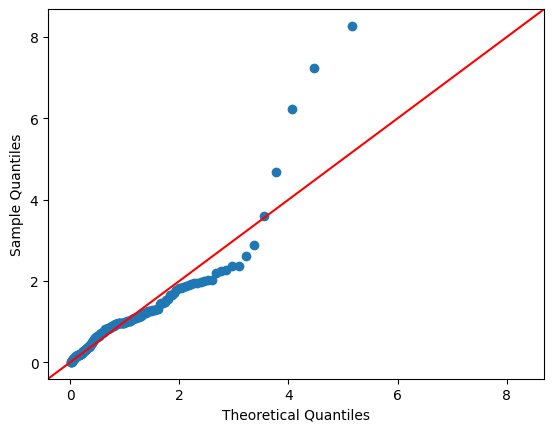

In [ ]:
# Create a Q-Q plot for the exponential-decay fit by
# first transforming the points to a unit-rate Poisson
# process as outlined by the random time change theorem
tsShifted = hawkes.exp_hawkes_compensators(t_arrDV0, 𝛉_exp)
iat = np.diff(np.insert(tsShifted, 0, 0))
qqplot(iat, dist=stats.expon, fit=False, line="45")
plt.show()

In [ ]:
def simulate_hawkes_exp(mu, alpha, beta, T, seed=None):
    """
    Simulate a univariate Hawkes process with exponential kernel on [0, T].

    Parameters
    ----------
    mu : float
        Baseline intensity (μ > 0).
    alpha : float
        Excitation jump size (α >= 0).
    beta : float
        Exponential decay rate (β > 0).
    T : float
        Time horizon for simulation.
    seed : int, optional
        Random seed for reproducibility.

    Returns
    -------
    events : list of float
        Event times simulated on [0, T].
    """
    if seed is not None:
        np.random.seed(seed)

    events = []
    t = 0.0
    # current total intensity upper bound
    M = mu

    # Keep track of past events for intensity calculation
    past_events = []

    while True:
        # 1. Draw candidate from homogeneous Poisson rate M
        s = np.random.exponential(1.0 / M)
        t_candidate = t + s
        if t_candidate > T:
            break

        # 2. Compute conditional intensity λ(t_candidate)
        #    sum of past jumps decayed to t_candidate
        if past_events:
            decays = np.exp(-beta * (t_candidate - np.array(past_events)))
            lambda_tc = mu + alpha * np.sum(decays)
        else:
            lambda_tc = mu

        # 3. Thinning: accept with probability λ/ M
        if np.random.rand() <= lambda_tc / M:
            # accept event
            events.append(t_candidate)
            past_events.append(t_candidate)
            # update upper bound (max intensity right after the jump)
            M = mu + alpha * len(past_events)
        else:
            # no event: M may still decrease as decays proceed
            # but for simplicity, keep M = mu + alpha * len(past_events)
            pass

        # advance time
        t = t_candidate

    return events

# --- assume you have ts (event times in days), T (observation window), and 𝛉_exp from your fit ---
mu, alpha, beta = 𝛉_exp

# 1. Create a fine time grid over [0, T]
time_grid = np.linspace(0, 1.0, 1000)  # adjust 2000 for resolution

# 2. Compute the conditional intensity λ(t) = μ + sum_i α e^{-β (t - t_i)} for t > t_i
#    We vectorize by computing the kernel matrix between grid and events:
dt = time_grid[:, None] - t_arrDV0[None, :]     # shape (2000, n_events)
dt[dt < 0] = np.nan                       # ignore future events
intensity = mu + alpha * np.nansum(np.exp(-beta * dt), axis=1)


events = np.array(simulate_hawkes_exp(mu, alpha, beta, 1.0, seed=42))

dt_sim = time_grid[:, None] - events[None, :]     # shape (2000, n_events)
dt_sim[dt_sim < 0] = np.nan                       # ignore future events
intensity_sim = mu + alpha * np.nansum(np.exp(-beta * dt_sim), axis=1)


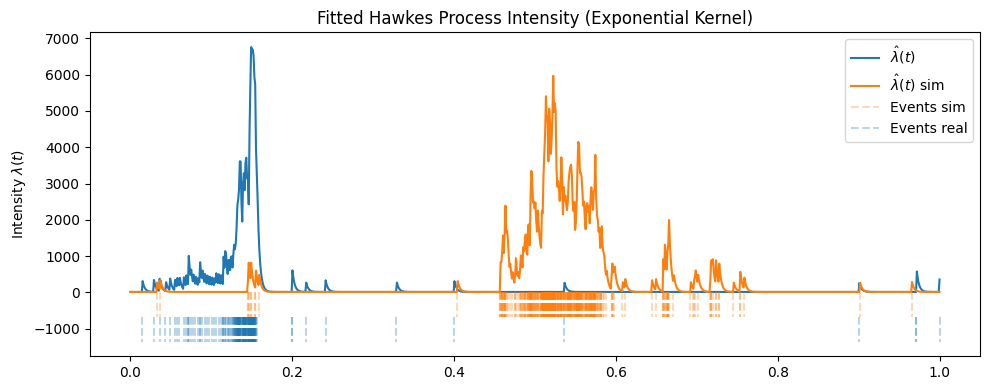

In [ ]:
# 3. Plotting
plt.figure(figsize=(10, 4))
plt.plot(time_grid, intensity, label=r'$\hat\lambda(t)$', color='C0')
plt.plot(time_grid, intensity_sim, label=r'$\hat\lambda(t)$ sim', color='C1')

plt.vlines(events, ymin=0, ymax=-np.max(intensity)*0.1, color='C1', alpha=0.3,
           linestyle='--', label='Events sim')
plt.vlines(t_arrDV0, ymin=-np.max(intensity)*0.1, ymax=-2*np.max(intensity)*0.1, color='C0', alpha=0.3,
           linestyle='--', label='Events real')
plt.ylabel('Intensity $\lambda(t)$')
plt.title('Fitted Hawkes Process Intensity (Exponential Kernel)')
plt.legend(loc='upper right')
plt.tight_layout()
#plt.xlim([15300,17000])
plt.show()